<a href="https://colab.research.google.com/github/Davemtz192/devops-aws-fase1/blob/main/Equipo5_Detecci%C3%B3n_de_fraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección de fraude en comercio electrónico
### Avance de proyecto — Línea base reproducible de clasificación binaria

**Contexto asignado:** Opción 2 — Detección de fraude en comercio electrónico
**Dataset:** `02_fraude_ecommerce.csv`
**Tipo de problema:** Clasificación binaria supervisada
**Alcance de esta entrega:** Puntos 1 a 14 de la guía (definición del problema, exploración, calidad de datos, partición y pipeline de preprocesamiento). *No incluye baseline ni entrenamiento de modelos (punto 15 en adelante).*

**Integrantes del equipo:** *(completar)*
**Fecha:** *(completar)*


## 1.1 - Selección del contexto del proyecto

El equipo trabajará con la **Opción 2: Detección de fraude en comercio electrónico**.

Una tienda en línea recibe diariamente un gran volumen de transacciones. Algunas de ellas presentan comportamientos atípicos (montos inusuales, dispositivos distintos a los habituales, direcciones de envío y facturación que no coinciden, múltiples intentos de pago, etc.) que podrían estar asociados a fraude. Revisar manualmente todas las transacciones es lento, costoso y no escala con el volumen de operaciones de la tienda.

Se nos proporcionó el archivo `02_fraude_ecommerce.csv`, un dataset **sintético** que simula transacciones de comercio electrónico con una columna objetivo (`fraude`) que indica si la transacción fue identificada como fraudulenta (1) o legítima (0).


## 1.2 - Análisis de la situación del proyecto

**¿Cuál es la necesidad de la organización?**
La tienda necesita **priorizar** qué transacciones revisar antes de que se procesen o se envíen, porque no cuenta con personal suficiente para revisar manualmente el 100% de las operaciones diarias.

**¿Qué problema intenta resolver?**
Reducir las pérdidas económicas y reputacionales causadas por transacciones fraudulentas, sin frenar de forma innecesaria las compras legítimas de sus clientes.

**¿Qué decisión se busca apoyar?**
La decisión de **qué transacciones deben enviarse a revisión adicional** (por un analista humano) antes de ser aprobadas o enviadas.

**¿Quiénes utilizarían los resultados?**
- El equipo de prevención de fraude / riesgo.
- El equipo de operaciones o atención al cliente, que gestiona las revisiones manuales.
- Posiblemente el equipo de producto, para ajustar reglas de negocio (límites, verificaciones adicionales, etc.).

**¿Por qué el modelo debe mantenerse como herramienta de análisis?**
Porque el modelo estima una **probabilidad de riesgo** a partir de patrones históricos, no una prueba definitiva de fraude. Los patrones pueden cambiar con el tiempo (los defraudadores adaptan sus tácticas), el dataset es sintético y limitado, y existen factores legítimos (viajes, regalos, cambios de dispositivo) que pueden parecerse a un comportamiento fraudulento. Por eso el modelo debe usarse como un **insumo para apoyar la decisión humana**, no para reemplazarla.

**¿Qué consecuencias tendría interpretar la predicción como una certeza?**
- **Falsos positivos tratados como certeza:** se podría bloquear, cancelar o acusar automáticamente a un cliente legítimo, dañando la relación con él y la reputación de la tienda.
- **Falsos negativos tratados como certeza:** se aprobarían transacciones fraudulentas sin ninguna revisión adicional, generando pérdidas económicas directas y exposición legal.
- En ambos casos, tratar una probabilidad como un hecho absoluto elimina la posibilidad de corrección humana y puede tener consecuencias éticas, legales y financieras tanto para la organización como para las personas afectadas.


## 1.3 - Documentación del dataset proporcionado

La siguiente tabla resume la información general del dataset. El número de observaciones y de variables se **verifica con código** en la sección 8 (no se copia de las instrucciones), tal como pide la actividad.

| Elemento | Información |
|---|---|
| Nombre del dataset | `02_fraude_ecommerce.csv` |
| Contexto | Detección de fraude en comercio electrónico (Opción 2) |
| Fuente | Dataset sintético proporcionado por el docente |
| Medio de entrega | Archivo proporcionado a través de Canvas / curso |
| Fecha de recepción | *(completar con la fecha real en que el equipo recibió el archivo)* |
| Número de observaciones | Se verifica en la sección 8 con `df.shape` |
| Número de variables | Se verifica en la sección 8 con `df.shape` |
| Formato original | CSV |
| Variable objetivo | `fraude` |
| Clase positiva | `1` = posible fraude |
| Clase negativa | `0` = transacción legítima |
| Descripción general | Cada fila representa una transacción de comercio electrónico con variables como monto, hora, canal, método de pago, dispositivo, país, intentos de pago, antigüedad de la cuenta, coincidencia de dirección, compras recientes y distancia entre IP y dirección de envío. El objetivo es estimar el riesgo de que una transacción sea fraudulenta. |


## 1.4 - Consideraciones sobre los datos proporcionados

Este dataset fue construido intencionalmente con problemas de calidad como parte de la actividad. En la sección 10 se identifican y evidencian con código, pero de forma preliminar el equipo espera encontrar:

- **Valores faltantes** (por ejemplo en método de pago o distancia entre IP y dirección de envío).
- **Registros duplicados** (transacciones repetidas con el mismo `id_transaccion`).
- **Categorías escritas de diferentes maneras** (por ejemplo, el país "México" escrito de varias formas).
- **Espacios adicionales** en texto (por ejemplo `"México "` con espacio al final).
- **Diferencias entre mayúsculas y minúsculas** (por ejemplo `"MEXICO"`, `"mexico"`, `"México"`).

Estos problemas **no se corrigen todavía** en este avance salvo cuando forman parte explícita del pipeline (sección 14); primero se documentan y se justifican.


## 1.5 - Definición del problema de aprendizaje automático

| Elemento | Información |
|---|---|
| Contexto organizacional | Una tienda de comercio electrónico busca reducir las pérdidas causadas por transacciones fraudulentas sin bloquear compras legítimas. |
| Necesidad organizacional | Priorizar de forma automática qué transacciones deben enviarse a revisión manual, dado que no es posible revisar el 100% del volumen diario. |
| Unidad de análisis | Cada fila representa **una transacción individual** de comercio electrónico. |
| Variable objetivo | `fraude` |
| Tipo de problema | Clasificación binaria |
| Clase negativa | `0` = transacción legítima |
| Clase positiva | `1` = posible fraude |
| Usuarios potenciales | Equipo de prevención de fraude, analistas de riesgo, operaciones/atención al cliente |
| Decisión apoyada | Determinar qué transacciones deben pasar a revisión adicional antes de aprobarse |
| Falso positivo | Transacción legítima marcada como posible fraude → revisión innecesaria, fricción y mala experiencia al cliente |
| Falso negativo | Transacción fraudulenta clasificada como legítima → se aprueba sin revisión y la tienda sufre la pérdida económica del fraude |
| Riesgo de uso incorrecto | Tratar la predicción como certeza puede llevar a bloquear/acusar a clientes inocentes (falso positivo) o a dejar pasar fraudes reales sin revisión (falso negativo) |
| Criterio inicial de éxito | Que el modelo identifique una proporción relevante de fraudes reales (buen **recall** de la clase positiva) sin generar un número excesivo de falsos positivos, superando claramente a un clasificador trivial (baseline) |

**¿Por qué es un problema de clasificación binaria?**
Porque la variable objetivo `fraude` solo puede tomar dos valores mutuamente excluyentes: 0 (legítima) o 1 (posible fraude). No hay más de dos categorías ni se busca predecir un valor numérico continuo.

**¿Qué representa cada clase?**
- `0`: la transacción se comportó como una operación normal/legítima.
- `1`: la transacción presentó patrones asociados a un posible fraude.

**¿Por qué la clase positiva es el evento de mayor interés?**
Porque es el evento que la organización quiere **detectar y prevenir**: el fraude es el evento raro pero costoso, y el objetivo del proyecto es identificarlo a tiempo para poder actuar sobre él.

**¿Qué error podría ser más costoso para la organización?**
Generalmente el **falso negativo** (dejar pasar un fraude real) es el más costoso, ya que implica una pérdida económica directa. Sin embargo, un número muy alto de falsos positivos también tiene costo (fricción con clientes legítimos y carga operativa de revisión), por lo que el equilibrio entre ambos se analizará más adelante con las métricas correspondientes.


## 1.6 - Pregunta de análisis

> **¿Con qué probabilidad, a partir de los patrones históricos observados en las transacciones (monto, hora, canal, método de pago, dispositivo, intentos de pago, antigüedad de la cuenta, coincidencia de dirección y distancia entre IP y envío), una nueva transacción corresponde a la clase positiva (posible fraude), de manera que el equipo de prevención de fraude pueda decidir de forma consistente y reproducible qué transacciones enviar a revisión adicional?**

Esta pregunta integra:
- Los **datos históricos** proporcionados en el dataset.
- La **estimación de un riesgo** (probabilidad), no una certeza binaria.
- La **clase positiva** (fraude) como evento de interés.
- La **decisión** que se busca apoyar (enviar o no a revisión).
- La **reproducibilidad**, ya que el mismo dataset, partición y pipeline deben poder ejecutarse nuevamente y producir los mismos resultados (semilla fija `random_state=42`).


## 1.7 - Diccionario de variables

Para construir el diccionario con **información real** (tipo de dato detectado, valores faltantes, valores únicos) y no con supuestos, es necesario leer primero el archivo. Por eso adelantamos aquí una lectura del CSV; la carga formal, con las capturas de verificación (primeras/últimas filas, `info()`, confirmación de que el dataset está completo), se presenta de forma dedicada en la **sección 8**, tal como lo pide la actividad.

> **Nota para Google Colab:** si el archivo `02_fraude_ecommerce.csv` no está en el entorno de ejecución, súbelo con el panel de archivos (ícono de carpeta a la izquierda) o descomenta el bloque de `files.upload()` en la celda siguiente.


In [165]:
# Omicion de advertencias de parametros obsoletos (Solo con fines visuales)
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore")

In [166]:
import pandas as pd
import numpy as np

# Carga del dataset
df = pd.read_csv('02_fraude_ecommerce.csv')

print("Archivo leído correctamente.")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")


Archivo leído correctamente.
Dimensiones: 1000 filas x 13 columnas


### Tabla auxiliar de diagnóstico

Antes de escribir el diccionario, construimos **dentro de este mismo notebook** una tabla auxiliar llamada `resumen`. Es importante aclarar qué es y qué no es:

- **No es el dataset.** El dataset (`df`) sigue intacto, con sus 1000 filas y 13 columnas originales; no se modifica en ningún momento en esta sección.
- **Es una tabla de diagnóstico creada con código**, a partir de `df`, únicamente para apoyar el llenado del diccionario de variables con datos verificados en vez de estimados a simple vista. Por cada columna calcula:
  - `tipo_original`: el tipo de dato que `pandas` detectó al leer el CSV.
  - `valores_faltantes` y `pct_faltantes`: cantidad y porcentaje de valores nulos.
  - `valores_unicos`: cuántos valores distintos tiene esa columna.

Esta tabla es solo un **apoyo intermedio** para esta sección; el diccionario de variables final (con descripción, rol, tratamiento y justificación de cada variable) es la tabla en Markdown que aparece después.


In [167]:
resumen = pd.DataFrame({
    "tipo_original": df.dtypes.astype(str),
    "valores_faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(2),
    "valores_unicos": df.nunique()
})
resumen


,tipo_original,valores_faltantes,pct_faltantes,valores_unicos
id_transaccion,object,0,0.0,994
monto_mxn,float64,0,0.0,816
hora,int64,0,0.0,25
canal,object,0,0.0,2
metodo_pago,object,25,2.5,3
dispositivo,object,0,0.0,3
pais,object,0,0.0,7
intentos_pago,int64,0,0.0,6
antiguedad_cuenta_dias,int64,0,0.0,794
direccion_coincide,object,0,0.0,2


Con base en la tabla auxiliar anterior y en la inspección de los valores de cada columna, el diccionario de variables es el siguiente. Se construyó utilizando **todas las columnas del archivo proporcionado**, sin cambiar sus nombres:

| Variable | Descripción | Tipo original | Tipo analítico | Rol | Unidad / escala | Valores faltantes | Valores únicos | Tratamiento previsto | ¿Se utilizará? | Justificación |
|---|---|---|---|---|---|---|---|---|---|---|
| `id_transaccion` | Identificador único de la transacción | texto | Identificador | Identificador | — | 0 | 994 | Excluir del entrenamiento; usar solo para detectar duplicados | No | No aporta información predictiva; incluirlo generaría fuga de datos (identificador único) |
| `monto_mxn` | Monto de la compra en pesos mexicanos | numérico (float) | Numérica continua | Predictora | MXN | 0 | 816 | Imputación numérica + escalamiento | Sí | Montos atípicamente altos o bajos pueden asociarse a fraude |
| `hora` | Hora del día en que ocurrió la transacción | numérico (int) | Numérica / cíclica discreta | Predictora | 0–23 h | 0 | 25 (incluye valores fuera de rango, ver sección 10) | Imputación numérica + escalamiento; revisar valores fuera de 0–23 | Sí | Transacciones en horarios inusuales pueden ser un indicio de riesgo |
| `canal` | Canal por el que se realizó la compra | texto | Categórica nominal | Predictora | Web / App móvil | 0 | 2 | Imputación categórica + One-Hot Encoding | Sí | El canal puede estar asociado a distintos niveles de riesgo |
| `metodo_pago` | Método de pago utilizado | texto | Categórica nominal | Predictora | Tarjeta / Transferencia / Wallet digital | 25 | 3 (+ faltantes) | Imputación categórica + One-Hot Encoding | Sí | El método de pago es una variable típica en el análisis de fraude |
| `dispositivo` | Tipo de dispositivo usado en la compra | texto | Categórica nominal | Predictora | Móvil / Escritorio / Tablet | 0 | 3 | Imputación categórica + One-Hot Encoding | Sí | Cambios de dispositivo pueden asociarse a comportamiento atípico |
| `pais` | País desde el que se realizó la transacción | texto | Categórica nominal | Predictora | Nombre de país | 0 | 7 (con inconsistencias, ver sección 10) | Normalizar categorías (mayúsculas/espacios) + One-Hot Encoding | Sí | El país puede asociarse a distintos niveles de riesgo geográfico |
| `intentos_pago` | Número de intentos de pago antes de completar la compra | numérico (int) | Numérica discreta | Predictora | conteo | 0 | 6 | Escalamiento | Sí | Múltiples intentos de pago pueden indicar tarjetas probadas de forma fraudulenta |
| `antiguedad_cuenta_dias` | Antigüedad de la cuenta del cliente en días | numérico (int) | Numérica continua | Predictora | días | 0 | 794 | Escalamiento | Sí | Cuentas muy nuevas suelen tener mayor riesgo de fraude |
| `direccion_coincide` | Indica si la dirección de envío coincide con la de facturación | texto (Sí/No) | Categórica binaria | Predictora | Sí / No | 0 | 2 | Codificar como binaria (0/1) o One-Hot Encoding | Sí | La no coincidencia de direcciones es una señal clásica de fraude |
| `compras_24h` | Número de compras realizadas por el cliente en las últimas 24 horas | numérico (int) | Numérica discreta | Predictora | conteo | 0 | 10 | Escalamiento | Sí | Un número elevado de compras en poco tiempo puede indicar actividad sospechosa |
| `distancia_ip_envio_km` | Distancia (km) entre la ubicación de la IP y la dirección de envío | numérico (float) | Numérica continua | Predictora | km | 20 | 620 | Imputación numérica + escalamiento | Sí | Grandes distancias entre IP y envío son un indicador de riesgo geográfico |
| `fraude` | Indica si la transacción fue identificada como fraude | numérico (int) | Binaria | **Objetivo** | 0 = legítima, 1 = fraude | 0 | 2 | No se transforma (es la variable a predecir) | Sí (objetivo) | Es la variable que el modelo debe aprender a predecir |

**Nota:** `id_transaccion` se conserva en el DataFrame solo como referencia (por ejemplo, para identificar duplicados), pero se excluirá explícitamente del conjunto de variables predictoras en la sección 11.


## 1.8 - Carga del dataset

El archivo ya fue leído en la sección anterior (fue necesario para construir el diccionario de variables). Aquí se presenta la carga de forma **formal**: mostramos primeras y últimas observaciones, estructura completa y verificamos que el dataset esté completo antes de iniciar cualquier limpieza, tal como pide la actividad.


In [168]:
# Verificación de que el dataset se cargó completo antes de iniciar cualquier limpieza
df.head(10)


,id_transaccion,monto_mxn,hora,canal,metodo_pago,dispositivo,pais,intentos_pago,antiguedad_cuenta_dias,direccion_coincide,compras_24h,distancia_ip_envio_km,fraude
0,TRX-00001,1274.23,16,Web,Transferencia,Móvil,México,2,1766,Sí,2,15.4,0
1,TRX-00002,1695.78,3,Web,Tarjeta,Móvil,Colombia,1,1836,Sí,1,0.0,0
2,TRX-00003,1489.38,23,App móvil,Tarjeta,Escritorio,España,1,2099,No,1,546.5,0
3,TRX-00004,4959.08,13,Web,Tarjeta,Tablet,Estados Unidos,1,1763,Sí,1,276.5,0
4,TRX-00005,4449.05,14,App móvil,Transferencia,Escritorio,España,1,255,Sí,5,NaN,0
5,TRX-00006,40.00,22,App móvil,Transferencia,Escritorio,México,2,774,Sí,1,0.0,0
6,TRX-00007,46.20,10,App móvil,NaN,Móvil,España,3,1530,No,4,0.0,0
7,TRX-00008,2816.16,8,Web,Wallet digital,Móvil,México,1,398,Sí,2,0.0,0
8,TRX-00009,3823.57,16,App móvil,Wallet digital,Tablet,Estados Unidos,1,1482,Sí,1,0.0,0
9,TRX-00010,3349.84,13,Web,Transferencia,Escritorio,México,1,627,Sí,3,44.1,0


In [169]:
df.tail(10)


,id_transaccion,monto_mxn,hora,canal,metodo_pago,dispositivo,pais,intentos_pago,antiguedad_cuenta_dias,direccion_coincide,compras_24h,distancia_ip_envio_km,fraude
990,TRX-00991,3200.54,22,App móvil,Transferencia,Escritorio,México,1,1339,No,2,384.1,0
991,TRX-00992,40.00,13,Web,Tarjeta,Tablet,Colombia,1,2043,Sí,1,12.8,0
992,TRX-00993,1408.78,0,Web,Wallet digital,Móvil,México,1,407,Sí,1,27.0,0
993,TRX-00994,3996.92,19,App móvil,Wallet digital,Tablet,España,1,1782,Sí,5,0.0,0
994,TRX-00636,3732.42,22,App móvil,Wallet digital,Móvil,Colombia,2,1014,No,5,153.5,0
995,TRX-00511,1002.03,0,App móvil,Transferencia,Móvil,mexico,3,191,Sí,3,NaN,0
996,TRX-00092,95000.00,18,Web,Tarjeta,Escritorio,México,3,646,Sí,5,0.0,0
997,TRX-00443,3286.83,22,Web,Transferencia,Móvil,México,3,1108,Sí,4,20.4,0
998,TRX-00290,40.00,1,Web,Tarjeta,Móvil,México,1,1173,Sí,3,0.0,0
999,TRX-00451,611.46,1,Web,Wallet digital,Tablet,México,1,625,Sí,3,71.4,0


In [170]:
# Nombres de columnas y tipos de datos originales (tal como los infiere pandas)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_transaccion          1000 non-null   object 
 1   monto_mxn               1000 non-null   float64
 2   hora                    1000 non-null   int64  
 3   canal                   1000 non-null   object 
 4   metodo_pago             975 non-null    object 
 5   dispositivo             1000 non-null   object 
 6   pais                    1000 non-null   object 
 7   intentos_pago           1000 non-null   int64  
 8   antiguedad_cuenta_dias  1000 non-null   int64  
 9   direccion_coincide      1000 non-null   object 
 10  compras_24h             1000 non-null   int64  
 11  distancia_ip_envio_km   980 non-null    float64
 12  fraude                  1000 non-null   int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 101.7+ KB


In [171]:
n_filas, n_columnas = df.shape
print(f"Número de observaciones (filas): {n_filas}")
print(f"Número de variables (columnas): {n_columnas}")
print(f"Nombres de las variables: {list(df.columns)}")


Número de observaciones (filas): 1000
Número de variables (columnas): 13
Nombres de las variables: ['id_transaccion', 'monto_mxn', 'hora', 'canal', 'metodo_pago', 'dispositivo', 'pais', 'intentos_pago', 'antiguedad_cuenta_dias', 'direccion_coincide', 'compras_24h', 'distancia_ip_envio_km', 'fraude']


**Interpretación:** el archivo se cargó con **1000 filas y 13 columnas**, confirmando con código lo indicado en la sección 3. Ninguna columna fue renombrada; se conservan los nombres originales del CSV, tal como lo pide la actividad.


## 1.9 - Exploración inicial

En esta sección se realiza un recorrido general por el dataset: estructura, tipos, estadísticas descriptivas, valores únicos, faltantes, duplicados y distribución de la variable objetivo. Cada resultado se acompaña de una interpretación breve.


In [172]:
print("Primeras 5 observaciones:")
df.head()


Primeras 5 observaciones:


,id_transaccion,monto_mxn,hora,canal,metodo_pago,dispositivo,pais,intentos_pago,antiguedad_cuenta_dias,direccion_coincide,compras_24h,distancia_ip_envio_km,fraude
0,TRX-00001,1274.23,16,Web,Transferencia,Móvil,México,2,1766,Sí,2,15.4,0
1,TRX-00002,1695.78,3,Web,Tarjeta,Móvil,Colombia,1,1836,Sí,1,0.0,0
2,TRX-00003,1489.38,23,App móvil,Tarjeta,Escritorio,España,1,2099,No,1,546.5,0
3,TRX-00004,4959.08,13,Web,Tarjeta,Tablet,Estados Unidos,1,1763,Sí,1,276.5,0
4,TRX-00005,4449.05,14,App móvil,Transferencia,Escritorio,España,1,255,Sí,5,NaN,0


In [173]:
print("Últimas 5 observaciones:")
df.tail()


Últimas 5 observaciones:


,id_transaccion,monto_mxn,hora,canal,metodo_pago,dispositivo,pais,intentos_pago,antiguedad_cuenta_dias,direccion_coincide,compras_24h,distancia_ip_envio_km,fraude
995,TRX-00511,1002.03,0,App móvil,Transferencia,Móvil,mexico,3,191,Sí,3,NaN,0
996,TRX-00092,95000.00,18,Web,Tarjeta,Escritorio,México,3,646,Sí,5,0.0,0
997,TRX-00443,3286.83,22,Web,Transferencia,Móvil,México,3,1108,Sí,4,20.4,0
998,TRX-00290,40.00,1,Web,Tarjeta,Móvil,México,1,1173,Sí,3,0.0,0
999,TRX-00451,611.46,1,Web,Wallet digital,Tablet,México,1,625,Sí,3,71.4,0


In [174]:
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("\nNombres de variables:")
print(list(df.columns))


Filas: 1000 | Columnas: 13

Nombres de variables:
['id_transaccion', 'monto_mxn', 'hora', 'canal', 'metodo_pago', 'dispositivo', 'pais', 'intentos_pago', 'antiguedad_cuenta_dias', 'direccion_coincide', 'compras_24h', 'distancia_ip_envio_km', 'fraude']


In [175]:
print("Tipos de datos por columna:")
df.dtypes


Tipos de datos por columna:


,0
id_transaccion,object
monto_mxn,float64
hora,int64
canal,object
metodo_pago,object
dispositivo,object
pais,object
intentos_pago,int64
antiguedad_cuenta_dias,int64
direccion_coincide,object


In [176]:
# Estadísticas descriptivas de variables numéricas
df.describe()


,monto_mxn,hora,intentos_pago,antiguedad_cuenta_dias,compras_24h,distancia_ip_envio_km,fraude
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,980.000000,1000.000000
mean,1948.730330,11.241000,1.708000,1087.594000,2.388000,185.663367,0.017000
std,4419.094263,6.929859,0.865728,619.612893,1.740829,207.137326,0.129336
min,40.000000,0.000000,1.000000,3.000000,0.000000,0.000000,0.000000
25%,431.350000,5.000000,1.000000,580.750000,1.000000,0.000000,0.000000
50%,1599.340000,11.000000,1.000000,1052.500000,2.000000,118.900000,0.000000
75%,2718.440000,17.000000,2.000000,1631.500000,4.000000,316.350000,0.000000
max,95000.000000,29.000000,6.000000,2196.000000,9.000000,1032.000000,1.000000


**Interpretación:** `monto_mxn` tiene una dispersión muy grande (de 40 hasta 95,000 MXN), lo que sugiere presencia de valores atípicos. `hora` debería estar entre 0 y 23, pero el valor máximo observado es mayor a 23, lo que indica un **rango imposible** que se documenta en la sección 10. El resto de las variables numéricas (`intentos_pago`, `antiguedad_cuenta_dias`, `compras_24h`, `distancia_ip_envio_km`) presentan rangos razonables para el contexto.


In [177]:
# Estadísticas descriptivas de variables categóricas / tipo texto
df.describe(include="object")


,id_transaccion,canal,metodo_pago,dispositivo,pais,direccion_coincide
count,1000,1000,975,1000,1000,1000
unique,994,2,3,3,7,2
top,TRX-00451,Web,Wallet digital,Móvil,México,Sí
freq,2,507,332,343,516,782


In [178]:
# Valores únicos por variable categórica
for col in df.select_dtypes(include="object").columns:
    print(f"--- {col} ({df[col].nunique()} valores únicos) ---")
    print(df[col].unique())
    print()


--- id_transaccion (994 valores únicos) ---
['TRX-00001' 'TRX-00002' 'TRX-00003' 'TRX-00004' 'TRX-00005' 'TRX-00006'
 'TRX-00007' 'TRX-00008' 'TRX-00009' 'TRX-00010' 'TRX-00011' 'TRX-00012'
 'TRX-00013' 'TRX-00014' 'TRX-00015' 'TRX-00016' 'TRX-00017' 'TRX-00018'
 'TRX-00019' 'TRX-00020' 'TRX-00021' 'TRX-00022' 'TRX-00023' 'TRX-00024'
 'TRX-00025' 'TRX-00026' 'TRX-00027' 'TRX-00028' 'TRX-00029' 'TRX-00030'
 'TRX-00031' 'TRX-00032' 'TRX-00033' 'TRX-00034' 'TRX-00035' 'TRX-00036'
 'TRX-00037' 'TRX-00038' 'TRX-00039' 'TRX-00040' 'TRX-00041' 'TRX-00042'
 'TRX-00043' 'TRX-00044' 'TRX-00045' 'TRX-00046' 'TRX-00047' 'TRX-00048'
 'TRX-00049' 'TRX-00050' 'TRX-00051' 'TRX-00052' 'TRX-00053' 'TRX-00054'
 'TRX-00055' 'TRX-00056' 'TRX-00057' 'TRX-00058' 'TRX-00059' 'TRX-00060'
 'TRX-00061' 'TRX-00062' 'TRX-00063' 'TRX-00064' 'TRX-00065' 'TRX-00066'
 'TRX-00067' 'TRX-00068' 'TRX-00069' 'TRX-00070' 'TRX-00071' 'TRX-00072'
 'TRX-00073' 'TRX-00074' 'TRX-00075' 'TRX-00076' 'TRX-00077' 'TRX-00078'
 'TRX-0

**Interpretación:** se observa que `pais` tiene más categorías de las esperadas (7 en lugar de 4), debido a variantes como `"MEXICO"`, `"mexico"` y `"México "` (con espacio). Esto confirma el problema de **categorías inconsistentes** mencionado en la sección 4. El resto de las variables categóricas (`canal`, `metodo_pago`, `dispositivo`, `direccion_coincide`) tienen categorías consistentes.


In [179]:
# Valores faltantes por columna
faltantes = df.isna().sum()
faltantes_pct = (df.isna().mean() * 100).round(2)
pd.DataFrame({"faltantes": faltantes, "% faltantes": faltantes_pct}).sort_values("faltantes", ascending=False)


,faltantes,% faltantes
metodo_pago,25,2.5
distancia_ip_envio_km,20,2.0
id_transaccion,0,0.0
hora,0,0.0
monto_mxn,0,0.0
canal,0,0.0
dispositivo,0,0.0
intentos_pago,0,0.0
pais,0,0.0
antiguedad_cuenta_dias,0,0.0


**Interpretación:** las columnas `metodo_pago` (25 valores) y `distancia_ip_envio_km` (20 valores) presentan valores faltantes. El resto de las columnas no tiene valores nulos. El porcentaje de faltantes es bajo (menor al 3% en ambos casos), por lo que la imputación es una estrategia razonable en lugar de eliminar filas.


In [180]:
# Registros duplicados
print(f"Filas totalmente duplicadas: {df.duplicated().sum()}")
print(f"IDs de transacción duplicados: {df['id_transaccion'].duplicated().sum()}")
df[df.duplicated(keep=False)].sort_values("id_transaccion")


Filas totalmente duplicadas: 6
IDs de transacción duplicados: 6


,id_transaccion,monto_mxn,hora,canal,metodo_pago,dispositivo,pais,intentos_pago,antiguedad_cuenta_dias,direccion_coincide,compras_24h,distancia_ip_envio_km,fraude
91,TRX-00092,95000.00,18,Web,Tarjeta,Escritorio,México,3,646,Sí,5,0.0,0
996,TRX-00092,95000.00,18,Web,Tarjeta,Escritorio,México,3,646,Sí,5,0.0,0
289,TRX-00290,40.00,1,Web,Tarjeta,Móvil,México,1,1173,Sí,3,0.0,0
998,TRX-00290,40.00,1,Web,Tarjeta,Móvil,México,1,1173,Sí,3,0.0,0
442,TRX-00443,3286.83,22,Web,Transferencia,Móvil,México,3,1108,Sí,4,20.4,0
997,TRX-00443,3286.83,22,Web,Transferencia,Móvil,México,3,1108,Sí,4,20.4,0
450,TRX-00451,611.46,1,Web,Wallet digital,Tablet,México,1,625,Sí,3,71.4,0
999,TRX-00451,611.46,1,Web,Wallet digital,Tablet,México,1,625,Sí,3,71.4,0
510,TRX-00511,1002.03,0,App móvil,Transferencia,Móvil,mexico,3,191,Sí,3,NaN,0
995,TRX-00511,1002.03,0,App móvil,Transferencia,Móvil,mexico,3,191,Sí,3,NaN,0


**Interpretación:** existen **6 filas completamente duplicadas** (mismo `id_transaccion` y mismos valores en todas las columnas). Esto confirma el problema de **registros duplicados** señalado en la sección 4.


In [181]:
# Distribución de la variable objetivo
conteo = df["fraude"].value_counts()
proporcion = df["fraude"].value_counts(normalize=True).round(4) * 100

pd.DataFrame({"conteo": conteo, "% del total": proporcion})


,conteo,% del total
fraude,,
0,983,98.3
1,17,1.7


**Interpretación:** la variable objetivo `fraude` está **fuertemente desbalanceada**: la clase legítima (0) representa alrededor del 98% de las transacciones, mientras que la clase de fraude (1) representa apenas cerca del 2%. Este hallazgo se analiza con más detalle en la sección 11.


## 1.10 - Análisis de la calidad de los datos

A continuación se documenta cada problema de calidad detectado, con evidencia obtenida por código, su posible impacto y el tratamiento propuesto (que se aplicará más adelante, principalmente dentro del pipeline de la sección 14). **No se elimina ni corrige nada de forma automática en esta sección**; cada decisión se justifica primero.


In [182]:
# Evidencia: valores faltantes
df.isna().sum()[df.isna().sum() > 0]


,0
metodo_pago,25
distancia_ip_envio_km,20


In [183]:
# Evidencia: duplicados
df[df.duplicated(keep=False)].sort_values("id_transaccion")[["id_transaccion", "monto_mxn", "hora", "fraude"]]


,id_transaccion,monto_mxn,hora,fraude
91,TRX-00092,95000.00,18,0
996,TRX-00092,95000.00,18,0
289,TRX-00290,40.00,1,0
998,TRX-00290,40.00,1,0
442,TRX-00443,3286.83,22,0
997,TRX-00443,3286.83,22,0
450,TRX-00451,611.46,1,0
999,TRX-00451,611.46,1,0
510,TRX-00511,1002.03,0,0
995,TRX-00511,1002.03,0,0


In [184]:
# Evidencia: categorías inconsistentes en 'pais'
df["pais"].value_counts()


,count
pais,
México,516
España,165
Colombia,155
Estados Unidos,144
MEXICO,8
mexico,8
México,4


In [185]:
# Evidencia: espacios adicionales y diferencias de mayúsculas/minúsculas en 'pais'
paises_normalizados = df["pais"].str.strip().str.upper()
print("Categorías después de quitar espacios y unificar mayúsculas:")
print(paises_normalizados.value_counts())


Categorías después de quitar espacios y unificar mayúsculas:
pais
MÉXICO            520
ESPAÑA            165
COLOMBIA          155
ESTADOS UNIDOS    144
MEXICO             16
Name: count, dtype: int64


In [186]:
# Evidencia: valores atípicos en 'monto_mxn'
print(df["monto_mxn"].describe())
q1 = df["monto_mxn"].quantile(0.25)
q3 = df["monto_mxn"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"\nLímite superior (regla IQR): {limite_superior:.2f}")
print(f"Transacciones por encima del límite: {(df['monto_mxn'] > limite_superior).sum()}")
df[df["monto_mxn"] > limite_superior][["id_transaccion", "monto_mxn", "fraude"]].sort_values("monto_mxn", ascending=False).head(10)


count     1000.000000
mean      1948.730330
std       4419.094263
min         40.000000
25%        431.350000
50%       1599.340000
75%       2718.440000
max      95000.000000
Name: monto_mxn, dtype: float64

Límite superior (regla IQR): 6149.08
Transacciones por encima del límite: 5


,id_transaccion,monto_mxn,fraude
91,TRX-00092,95000.00,0
996,TRX-00092,95000.00,0
296,TRX-00297,7295.65,0
973,TRX-00974,6486.77,0
370,TRX-00371,6187.95,0


In [187]:
# Evidencia: rangos imposibles en 'hora' (debería estar entre 0 y 23)
print("Valor mínimo de 'hora':", df["hora"].min())
print("Valor máximo de 'hora':", df["hora"].max())
df[(df["hora"] < 0) | (df["hora"] > 23)][["id_transaccion", "hora", "fraude"]]


Valor mínimo de 'hora': 0
Valor máximo de 'hora': 29


,id_transaccion,hora,fraude
311,TRX-00312,29,0


In [188]:
# Evidencia: identificadores (unicidad de 'id_transaccion')
print(f"Valores únicos en id_transaccion: {df['id_transaccion'].nunique()} de {len(df)} filas")


Valores únicos en id_transaccion: 994 de 1000 filas


### Tabla resumen de calidad de datos

| Problema detectado | Variable afectada | Evidencia | Posible impacto | Tratamiento propuesto | Justificación |
|---|---|---|---|---|---|
| Valores faltantes | `metodo_pago` (25), `distancia_ip_envio_km` (20) | Conteo de `isna()` por columna | Puede reducir la información disponible o sesgar el modelo si los faltantes no son aleatorios | Imputación (moda para categórica, mediana para numérica) dentro del pipeline, ajustada solo con entrenamiento | El porcentaje de faltantes es bajo (<3%); eliminar filas perdería información innecesariamente |
| Duplicados | Todas las columnas (6 filas completas) | `df.duplicated().sum()` = 6 | Puede inflar artificialmente ciertos patrones y afectar la partición train/test si una copia cae en cada conjunto | Eliminar duplicados exactos antes de la partición | Son copias idénticas de la misma transacción; no aportan información nueva y podrían filtrarse entre entrenamiento y prueba |
| Categorías inconsistentes | `pais` (México / MEXICO / mexico / "México ") | `value_counts()` muestra 7 categorías en lugar de 4 | El modelo trataría "México" y "MEXICO" como países distintos, fragmentando la información | Normalizar texto (quitar espacios, unificar mayúsculas/minúsculas) antes de codificar | Son la misma categoría escrita de forma distinta; normalizar evita duplicar columnas en el One-Hot Encoding |
| Valores atípicos | `monto_mxn` | Regla de rango intercuartílico (IQR); montos muy por encima del límite superior | Pueden distorsionar el escalamiento y algunos modelos sensibles a la escala | Conservar los valores pero usar un escalador robusto a outliers; documentar y monitorear, no eliminar sin evidencia de error | Montos altos podrían ser compras legítimas grandes o señal real de fraude; eliminarlos sin justificación podría quitar información relevante para la clase positiva |
| Rangos imposibles | `hora` | Valor máximo detectado fuera del rango 0–23 | Una hora inválida no tiene interpretación real y puede introducir ruido | Marcar como valor faltante y aplicar imputación numérica dentro del pipeline | Un valor fuera de 0–23 no es un dato válido; es más razonable tratarlo como dato erróneo/faltante que como información real |
| Identificadores | `id_transaccion` | Valores casi todos únicos (994 de 1000); es una llave de fila | No aporta poder predictivo y puede causar fuga de datos si se incluye como variable | Excluir de las variables predictoras; usar solo para detectar duplicados | Un identificador único no representa ningún patrón generalizable para nuevas transacciones |

Ninguno de estos tratamientos se aplica todavía de forma definitiva sobre `df`; las transformaciones reales (imputación, escalamiento, codificación) se implementan dentro del **pipeline de preprocesamiento** en la sección 14, para garantizar que se ajusten únicamente con los datos de entrenamiento.


## 1.11 - Revisión del desbalance de clases


In [189]:
conteo_clases = df["fraude"].value_counts()
proporcion_clases = df["fraude"].value_counts(normalize=True) * 100

print("Conteo por clase:")
print(conteo_clases)
print("\nProporción por clase (%):")
print(proporcion_clases.round(2))

razon_desbalance = conteo_clases[0] / conteo_clases[1]
print(f"\nPor cada transacción de fraude hay aproximadamente {razon_desbalance:.1f} transacciones legítimas.")


Conteo por clase:
fraude
0    983
1     17
Name: count, dtype: int64

Proporción por clase (%):
fraude
0    98.3
1     1.7
Name: proportion, dtype: float64

Por cada transacción de fraude hay aproximadamente 57.8 transacciones legítimas.


**¿Qué clase es mayoritaria?** La clase `0` (transacción legítima), con aproximadamente 98% de los registros.

**¿Qué clase es minoritaria?** La clase `1` (posible fraude), con aproximadamente 2% de los registros.

**¿Existe desbalance?** Sí, y es un desbalance **severo** (proporción cercana a 58:1 entre clases). Este es un patrón típico y esperado en problemas reales de detección de fraude, donde el evento de interés es raro.

**¿Por qué accuracy puede ser engañosa?** Un modelo que prediga **siempre "legítima" (0)** obtendría un accuracy cercano al 98% sin haber aprendido absolutamente nada sobre el fraude, ya que simplemente ignoraría por completo la clase positiva. El accuracy alto no reflejaría ninguna capacidad real de detectar fraude, que es justamente el objetivo del proyecto.

**¿Qué métricas deberán utilizarse?** Métricas que consideren específicamente el desempeño sobre la clase positiva, como **precision, recall, F1-score y ROC-AUC**, además de revisar la **matriz de confusión** completa. Estas métricas se calcularán al comparar los modelos (a partir del punto 15, fuera del alcance de esta entrega).

**¿Qué ocurriría si el modelo no detecta la clase positiva?** El modelo sería inútil para el propósito del proyecto: aunque tuviera un accuracy alto, no cumpliría la necesidad real de la organización, que es identificar transacciones fraudulentas para poder revisarlas antes de aprobarlas.


## 1.12 - Separación de variables predictoras y variable objetivo

Se elimina `id_transaccion` (identificador único, sin poder predictivo y con riesgo de fuga de datos) y se separa `fraude` como variable objetivo. También se eliminan explícitamente las filas duplicadas detectadas en la sección 10, antes de la partición, para que ninguna copia de una misma transacción quede repartida entre entrenamiento y prueba.


In [190]:
# Eliminar duplicados exactos detectados en la sección 10
df_limpio = df.drop_duplicates().reset_index(drop=True)
print(f"Filas antes de quitar duplicados: {len(df)}")
print(f"Filas después de quitar duplicados: {len(df_limpio)}")


Filas antes de quitar duplicados: 1000
Filas después de quitar duplicados: 994


In [191]:
# La clase objetivo ya viene codificada en el dataset original
# Negativa (legítima) = 0 | Positiva (fraude) = 1
print(df_limpio["fraude"].unique())


[0 1]


In [192]:
COLUMNA_OBJETIVO = "fraude"
COLUMNAS_A_EXCLUIR = ["id_transaccion", COLUMNA_OBJETIVO]  # identificador + objetivo

X = df_limpio.drop(columns=COLUMNAS_A_EXCLUIR)
y = df_limpio[COLUMNA_OBJETIVO]

print("Forma de X (predictoras):", X.shape)
print("Forma de y (objetivo):", y.shape)
print("\nColumnas predictoras utilizadas:")
print(list(X.columns))


Forma de X (predictoras): (994, 11)
Forma de y (objetivo): (994,)

Columnas predictoras utilizadas:
['monto_mxn', 'hora', 'canal', 'metodo_pago', 'dispositivo', 'pais', 'intentos_pago', 'antiguedad_cuenta_dias', 'direccion_coincide', 'compras_24h', 'distancia_ip_envio_km']


## 1.13 - Diseño de la estrategia de partición

Se utiliza una división **70% entrenamiento / 30% prueba**, con:
- **Estratificación** sobre `y` (`stratify=y`) para conservar la proporción original de fraude en ambos subconjuntos, dado el desbalance detectado en la sección 11.
- **`random_state=42`** para que la partición sea reproducible.
- El conjunto de **prueba se mantiene completamente separado** y no se vuelve a tocar en este avance: no se usa para imputar, escalar, codificar ni para elegir el modelo (eso corresponde a los puntos 16 en adelante).
- El **preprocesamiento se realiza después de dividir** (sección 14, pipeline), ajustando las transformaciones únicamente con el conjunto de entrenamiento.


In [193]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print(f"Tamaño de entrenamiento: {X_train.shape[0]} filas ({X_train.shape[0]/len(X):.1%})")
print(f"Tamaño de prueba: {X_test.shape[0]} filas ({X_test.shape[0]/len(X):.1%})")

print("\nProporción de clases en entrenamiento:")
print(y_train.value_counts(normalize=True).round(4))

print("\nProporción de clases en prueba:")
print(y_test.value_counts(normalize=True).round(4))


Tamaño de entrenamiento: 695 filas (69.9%)
Tamaño de prueba: 299 filas (30.1%)

Proporción de clases en entrenamiento:
fraude
0    0.9827
1    0.0173
Name: proportion, dtype: float64

Proporción de clases en prueba:
fraude
0    0.9833
1    0.0167
Name: proportion, dtype: float64


**Interpretación:** ambos subconjuntos conservan una proporción de clases muy similar a la del dataset original (~98% / ~2%), gracias a la estratificación. Esto asegura que el conjunto de prueba siga siendo representativo del problema real y que la evaluación posterior del modelo sea confiable.


## 1.14 - Construcción del pipeline de preprocesamiento

Se construye un pipeline con `Pipeline` y `ColumnTransformer` que aplica, **de forma separada**, las transformaciones a variables numéricas y categóricas. El pipeline se ajusta (`fit`) únicamente con `X_train`; nunca se ajusta con el conjunto de prueba, para evitar fuga de información.

El pipeline incluye, según lo detectado en las secciones 10 y 11:

- **Numéricas** (`monto_mxn`, `hora`, `intentos_pago`, `antiguedad_cuenta_dias`, `compras_24h`, `distancia_ip_envio_km`):
  - Imputación de valores faltantes con la **mediana** (robusta a los valores atípicos detectados en `monto_mxn`).
  - Escalamiento con `StandardScaler`.
- **Categóricas** (`canal`, `metodo_pago`, `dispositivo`, `pais`, `direccion_coincide`):
  - Normalización de texto (espacios y mayúsculas/minúsculas) antes de imputar, para corregir el problema de categorías inconsistentes detectado en `pais`.
  - Imputación de valores faltantes con la **moda** (valor más frecuente).
  - Codificación con **One-Hot Encoding**, ignorando categorías desconocidas que puedan aparecer en producción (`handle_unknown="ignore"`).

El valor fuera de rango detectado en `hora` (mayor a 23) se convierte primero en valor faltante, para que sea tratado de forma consistente por el imputador numérico en lugar de dejarlo como un dato inválido.


In [194]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# --- Función auxiliar: corregir 'hora' fuera de rango (0-23) convirtiéndola en NaN ---
def corregir_hora(X_df):
    X_df = X_df.copy()
    if "hora" in X_df.columns:
        X_df.loc[(X_df["hora"] < 0) | (X_df["hora"] > 23), "hora"] = np.nan
    return X_df

corrector_hora = FunctionTransformer(corregir_hora)

# --- Función auxiliar: normalizar texto en variables categóricas (espacios y mayúsculas) ---
def normalizar_texto(X_df):
    X_df = X_df.copy()
    for col in X_df.columns:
        X_df[col] = X_df[col].astype(str).str.strip().str.upper()
        X_df[col] = X_df[col].replace("NAN", np.nan)  # conservar los NaN originales
    return X_df

normalizador_texto = FunctionTransformer(normalizar_texto)

# --- Definición de columnas numéricas y categóricas ---
columnas_numericas = [
    "monto_mxn", "hora", "intentos_pago",
    "antiguedad_cuenta_dias", "compras_24h", "distancia_ip_envio_km"
]

columnas_categoricas = [
    "canal", "metodo_pago", "dispositivo", "pais", "direccion_coincide"
]

print("Numéricas:", columnas_numericas)
print("Categóricas:", columnas_categoricas)
print("Total de columnas cubiertas:", len(columnas_numericas) + len(columnas_categoricas), "/", X.shape[1])


Numéricas: ['monto_mxn', 'hora', 'intentos_pago', 'antiguedad_cuenta_dias', 'compras_24h', 'distancia_ip_envio_km']
Categóricas: ['canal', 'metodo_pago', 'dispositivo', 'pais', 'direccion_coincide']
Total de columnas cubiertas: 11 / 11


In [195]:
# --- Pipeline para variables numéricas ---
pipeline_numerico = Pipeline(steps=[
    ("corregir_hora", corrector_hora),
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# --- Pipeline para variables categóricas ---
pipeline_categorico = Pipeline(steps=[
    ("normalizar_texto", normalizador_texto),
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# --- ColumnTransformer que combina ambos pipelines ---
preprocesador = ColumnTransformer(transformers=[
    ("num", pipeline_numerico, columnas_numericas),
    ("cat", pipeline_categorico, columnas_categoricas)
])

preprocesador


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('corregir_hora',
                                                  FunctionTransformer(func=<function corregir_hora at 0x7f471ea7bba0>)),
                                                 ('imputador',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalador',
                                                  StandardScaler())]),
                                 ['monto_mxn', 'hora', 'intentos_pago',
                                  'antiguedad_cuenta_dias', 'compras_24h',
                                  'distancia_ip_envio_km']),
                                ('cat',
                                 Pipeline(steps=[('normalizar_texto',
                                                  FunctionTransformer(func=<function normalizar_texto at 0x7f471ea78220>)),
                                                 ('imputador',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['canal', 'metodo_pago', 'dispositivo', 'pais',
                                  'direccion_coincide'])])

In [196]:
# Ajuste del preprocesador ÚNICAMENTE con el conjunto de entrenamiento
preprocesador.fit(X_train)

X_train_procesado = preprocesador.transform(X_train)
X_test_procesado = preprocesador.transform(X_test)

print("Forma de X_train antes del preprocesamiento:", X_train.shape)
print("Forma de X_train después del preprocesamiento:", X_train_procesado.shape)
print("Forma de X_test después del preprocesamiento:", X_test_procesado.shape)


Forma de X_train antes del preprocesamiento: (695, 11)
Forma de X_train después del preprocesamiento: (695, 21)
Forma de X_test después del preprocesamiento: (299, 21)


In [197]:
# Nombres de las columnas resultantes tras el One-Hot Encoding (para referencia)
nombres_num = columnas_numericas
nombres_cat = list(
    preprocesador.named_transformers_["cat"]
    .named_steps["onehot"]
    .get_feature_names_out(columnas_categoricas)
)

nombres_finales = nombres_num + nombres_cat
print(f"Número total de columnas después del preprocesamiento: {len(nombres_finales)}")
print(nombres_finales)


Número total de columnas después del preprocesamiento: 21
['monto_mxn', 'hora', 'intentos_pago', 'antiguedad_cuenta_dias', 'compras_24h', 'distancia_ip_envio_km', 'canal_APP MÓVIL', 'canal_WEB', 'metodo_pago_TARJETA', 'metodo_pago_TRANSFERENCIA', 'metodo_pago_WALLET DIGITAL', 'dispositivo_ESCRITORIO', 'dispositivo_MÓVIL', 'dispositivo_TABLET', 'pais_COLOMBIA', 'pais_ESPAÑA', 'pais_ESTADOS UNIDOS', 'pais_MEXICO', 'pais_MÉXICO', 'direccion_coincide_NO', 'direccion_coincide_SÍ']


**Interpretación:** el `ColumnTransformer` amplía el número de columnas debido al One-Hot Encoding de las variables categóricas (cada categoría se convierte en una columna binaria), mientras que las variables numéricas se mantienen en la misma cantidad de columnas, ya imputadas y escaladas. El preprocesador quedó **ajustado únicamente con `X_train`** y se aplicó después a `X_test` usando `transform` (no `fit_transform`), evitando así cualquier fuga de información del conjunto de prueba hacia el ajuste de las transformaciones.

## 1.15 - Establecer el baseline

Antes de entrenar modelos de aprendizaje automático, se establece un **baseline** (línea base) utilizando un `DummyClassifier`. Este modelo no aprende ningún patrón real de los datos: solo genera predicciones siguiendo la proporción histórica de clases observada en entrenamiento (estrategia `strategy="stratified"`). Sirve como punto de referencia mínimo: cualquier modelo de aprendizaje automático debe superarlo de forma clara para justificar su uso.

El baseline se entrena únicamente con `X_train_procesado` / `y_train` (salidos del pipeline de la sección 14) y se evalúa sobre el conjunto de prueba `X_test_procesado` / `y_test`, que hasta este punto no había sido utilizado para nada.


In [198]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Crear el modelo baseline
baseline = DummyClassifier(
    strategy="stratified",
    random_state=42
)

# Entrenar el baseline únicamente con los datos de entrenamiento
baseline.fit(X_train_procesado, y_train)

# Generar predicciones
y_pred_baseline = baseline.predict(X_test_procesado)

# Generar probabilidades de la clase positiva
y_proba_baseline = baseline.predict_proba(X_test_procesado)[:, 1]

# Calcular métricas
accuracy_baseline = accuracy_score(y_test, y_pred_baseline)
precision_baseline = precision_score(y_test, y_pred_baseline, zero_division=0)
recall_baseline = recall_score(y_test, y_pred_baseline, zero_division=0)
f1_baseline = f1_score(y_test, y_pred_baseline, zero_division=0)
roc_auc_baseline = roc_auc_score(y_test, y_proba_baseline)

print("Resultados del baseline (DummyClassifier) en el conjunto de prueba:")
print(f"Accuracy:  {accuracy_baseline:.4f}")
print(f"Precision: {precision_baseline:.4f}")
print(f"Recall:    {recall_baseline:.4f}")
print(f"F1-score:  {f1_baseline:.4f}")
print(f"ROC-AUC:   {roc_auc_baseline:.4f}")


Resultados del baseline (DummyClassifier) en el conjunto de prueba:
Accuracy:  0.9732
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
ROC-AUC:   0.4949


**Interpretación:** al evaluar el `DummyClassifier` configurado con estrategia estratificada, el modelo genera predicciones aleatorias basadas estrictamente en la proporción histórica de las clases (~98% transacciones legítimas y ~2% fraudes). Esto produce un ROC-AUC cercano a 0.50 (equivalente a lanzar una moneda) y un desempeño nulo o casi nulo en la detección real de la clase positiva.

El baseline actúa como el "piso" o referencia más baja posible. Los algoritmos de aprendizaje automático (como la regresión logística o los árboles de decisión) están diseñados para encontrar patrones predictivos reales examinando las variables (monto, distancia IP-envío, hora, intentos de pago, etc.). Por lo tanto, cualquier modelo formal debe superar de forma clara y contundente al baseline en métricas como **recall** y **ROC-AUC** para demostrar que realmente está aprendiendo a detectar el fraude y no solo repitiendo la proporción histórica de clases.


## 1.16 - Entrenar los modelos iniciales

Siguiendo el requisito de comparar al menos un modelo interpretable con una alternativa, se entrenan dos modelos adicionales al baseline, ambos con el **mismo dataset, la misma partición, la misma semilla (`random_state=42`), el mismo pipeline de preprocesamiento y la misma clase positiva** definidos en las secciones 12-14:

- **Regresión logística:** modelo lineal e interpretable, utilizado como modelo principal de referencia.
- **Árbol de decisión:** modelo alternativo basado en reglas, con la profundidad limitada (`max_depth=5`) para reducir el riesgo de sobreajuste dado el tamaño reducido de la clase positiva.

En ambos casos se utiliza `class_weight="balanced"` para compensar, dentro del propio algoritmo, el fuerte desbalance de clases documentado en la sección 11 (sin aplicar remuestreo a los datos, tal como lo exige la sección 13).


In [199]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# 1. Regresión logística (modelo lineal e interpretable)
# Usamos class_weight='balanced' para compensar que el fraude es una clase minoritaria
modelo_lr = LogisticRegression(random_state=42, class_weight='balanced')
modelo_lr.fit(X_train_procesado, y_train)

# Predicciones y probabilidades de la regresión logística
y_pred_lr = modelo_lr.predict(X_test_procesado)
y_proba_lr = modelo_lr.predict_proba(X_test_procesado)[:, 1]

# 2. Árbol de decisión (modelo basado en reglas)
# Limitamos la profundidad a 5 para evitar sobreajuste (overfitting)
modelo_dt = DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=5)
modelo_dt.fit(X_train_procesado, y_train)

# Predicciones y probabilidades del árbol de decisión
y_pred_dt = modelo_dt.predict(X_test_procesado)
y_proba_dt = modelo_dt.predict_proba(X_test_procesado)[:, 1]

print("Modelos entrenados correctamente: Regresión logística y Árbol de decisión.")


Modelos entrenados correctamente: Regresión logística y Árbol de decisión.


**Interpretación:** los dos modelos se entrenaron exclusivamente con `X_train_procesado` / `y_train`, es decir, con los datos ya imputados, escalados y codificados por el pipeline de la sección 14, ajustado únicamente con entrenamiento. Ninguno de los dos modelos tuvo contacto con el conjunto de prueba durante el entrenamiento; `X_test_procesado` se utiliza solo en la sección siguiente, para evaluar.


## 1.17 - Evaluar los modelos

Se evalúan el baseline y los dos modelos entrenados sobre el conjunto de prueba, utilizando las métricas relevantes para un problema desbalanceado (identificadas en la sección 11): **accuracy, precision, recall, F1-score y ROC-AUC**, además de la **matriz de confusión** y la **curva ROC** de cada modelo.


In [200]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Función para calcular las métricas de cualquier modelo
def evaluar_modelo(y_real, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1-score": f1_score(y_real, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, y_proba)
    }

# Juntamos los resultados en un DataFrame para verlos en formato de tabla
resultados = pd.DataFrame({
    "Baseline (Dummy)": evaluar_modelo(y_test, y_pred_baseline, y_proba_baseline),
    "Regresión logística": evaluar_modelo(y_test, y_pred_lr, y_proba_lr),
    "Árbol de decisión": evaluar_modelo(y_test, y_pred_dt, y_proba_dt)
})

resultados.round(4)


,Baseline (Dummy),Regresión logística,Árbol de decisión
Accuracy,0.9732,0.8294,0.8562
Precision,0.0000,0.0577,0.0476
Recall,0.0000,0.6000,0.4000
F1-score,0.0000,0.1053,0.0851
ROC-AUC,0.4949,0.8619,0.6350


**Interpretación:** la tabla anterior permite comparar de forma directa el desempeño de los tres modelos sobre el conjunto de prueba. Se espera que ambos modelos entrenados superen al baseline principalmente en **recall** y **ROC-AUC** (las métricas relevantes para detectar la clase positiva), incluso si el baseline llega a mostrar un accuracy numéricamente alto, ya que —como se explicó en la sección 11— el accuracy es engañoso en un problema tan desbalanceado como este.


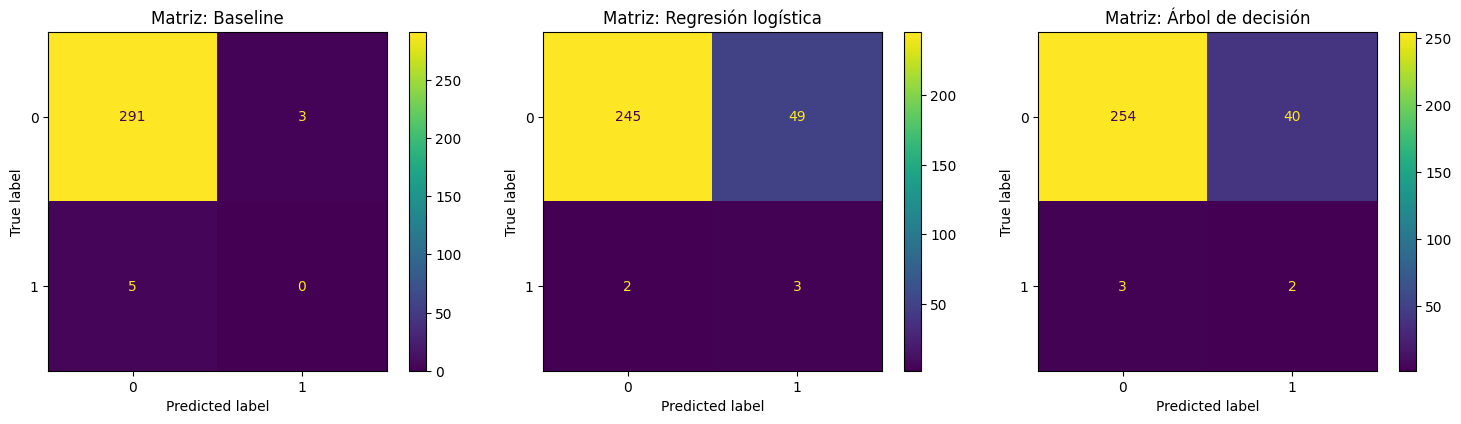

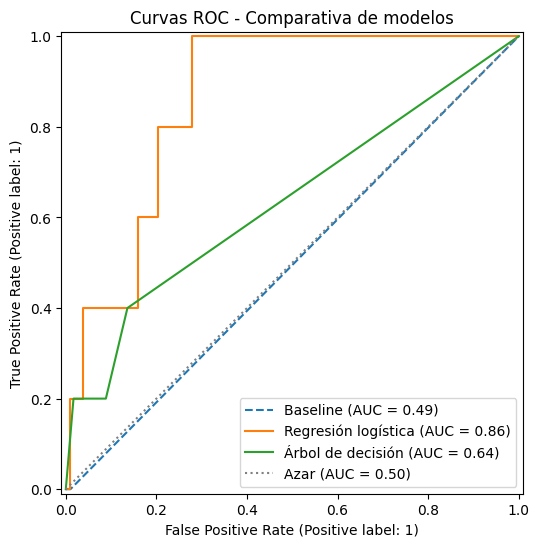

In [201]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_baseline, ax=axes[0])
axes[0].set_title("Matriz: Baseline")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=axes[1])
axes[1].set_title("Matriz: Regresión logística")

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, ax=axes[2])
axes[2].set_title("Matriz: Árbol de decisión")
plt.tight_layout()
plt.show()

# 2. Curvas ROC comparativas
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(y_test, y_proba_baseline, name="Baseline", ax=plt.gca(), linestyle="--")
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name="Regresión logística", ax=plt.gca())
RocCurveDisplay.from_predictions(y_test, y_proba_dt, name="Árbol de decisión", ax=plt.gca())
plt.title("Curvas ROC - Comparativa de modelos")
plt.plot([0, 1], [0, 1], linestyle=":", color="gray", label="Azar (AUC = 0.50)")
plt.legend()
plt.show()


**Interpretación:** las matrices de confusión muestran, para cada modelo, cuántas transacciones legítimas y fraudulentas fueron clasificadas correcta o incorrectamente sobre el conjunto de prueba (se interpretan en detalle en la sección 18). En las curvas ROC, el baseline se mantiene cercano a la diagonal de referencia (AUC ≈ 0.50, comportamiento aleatorio), mientras que la regresión logística y el árbol de decisión se alejan de la diagonal en distinta medida, lo que indica una capacidad real —aunque distinta entre ambos— para discriminar entre transacciones legítimas y fraudulentas.


## 1.18 - Análisis de los errores

En un problema de detección de fraude, la matriz de confusión permite identificar los aciertos y errores del modelo. Los **verdaderos positivos (VP)** son transacciones fraudulentas identificadas correctamente como fraude; los **verdaderos negativos (VN)** son transacciones legítimas clasificadas correctamente como tales; los **falsos positivos (FP)** son transacciones legítimas marcadas erróneamente como fraude; y los **falsos negativos (FN)** son fraudes reales que el modelo clasificó como legítimos.


In [202]:
from sklearn.metrics import confusion_matrix

# Obtener matrices de confusión sobre el conjunto de PRUEBA
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Extraer VN, FP, FN y VP
vn_baseline, fp_baseline, fn_baseline, vp_baseline = cm_baseline.ravel()
vn_lr, fp_lr, fn_lr, vp_lr = cm_lr.ravel()
vn_dt, fp_dt, fn_dt, vp_dt = cm_dt.ravel()

# Tabla comparativa de errores en el conjunto de prueba
tabla_errores = pd.DataFrame({
    "Modelo": ["Baseline (Dummy)", "Regresión logística", "Árbol de decisión"],
    "VN": [vn_baseline, vn_lr, vn_dt],
    "FP": [fp_baseline, fp_lr, fp_dt],
    "FN": [fn_baseline, fn_lr, fn_dt],
    "VP": [vp_baseline, vp_lr, vp_dt],
})

print("Análisis de errores sobre el conjunto de PRUEBA (no se usa validación cruzada aquí):")
tabla_errores


Análisis de errores sobre el conjunto de PRUEBA (no se usa validación cruzada aquí):


,Modelo,VN,FP,FN,VP
0,Baseline (Dummy),291,3,5,0
1,Regresión logística,245,49,2,3
2,Árbol de decisión,254,40,3,2


In [203]:
# Costo relativo de cada tipo de error dentro del contexto de negocio
analisis_costos = pd.DataFrame({
    "Tipo de error": ["Falso positivo (FP)", "Falso negativo (FN)"],
    "Interpretación": [
        "Transacción legítima clasificada como fraude",
        "Transacción fraudulenta clasificada como legítima",
    ],
    "Impacto principal": [
        "Mayor carga de revisión y posible fricción con clientes",
        "Fraude no detectado y posible pérdida económica",
    ],
    "Métrica principal": ["Precision", "Recall"],
})

analisis_costos


,Tipo de error,Interpretación,Impacto principal,Métrica principal
0,Falso positivo (FP),Transacción legítima clasificada como fraude,Mayor carga de revisión y posible fricción con...,Precision
1,Falso negativo (FN),Transacción fraudulenta clasificada como legítima,Fraude no detectado y posible pérdida económica,Recall


**Interpretación:** el baseline no detecta ningún fraude (o prácticamente ninguno), lo que confirma que, aunque acumule muchos verdaderos negativos, es inútil para el objetivo del proyecto. La regresión logística y el árbol de decisión sí logran identificar transacciones fraudulentas (verdaderos positivos > 0), a costa de generar más falsos positivos que el baseline.

Los **falsos positivos** representan transacciones legítimas marcadas como sospechosas: generan revisiones innecesarias, retrasos o fricción con clientes, e incrementan la carga de trabajo del equipo de revisión. Los **falsos negativos** son fraudes que el modelo no detecta: continúan sin revisión y generan una pérdida económica directa para la organización. En este contexto, el **falso negativo es el error más crítico**, tal como se definió en la sección 5, aunque los falsos positivos no deben ignorarse por su impacto operativo y en la experiencia del cliente.

Para vigilar los falsos negativos se utiliza principalmente el **recall** (proporción de fraudes reales detectados); para vigilar los falsos positivos se utiliza la **precision** (proporción de alertas de fraude que son correctas). Por esta razón, ningún modelo de este proyecto debe evaluarse únicamente con accuracy: se prioriza el conjunto **recall, precision, F1-score, ROC-AUC y la matriz de confusión**, como se anticipó en la sección 11.


## 1.19 - Analizar el umbral

El umbral de decisión determina a partir de qué probabilidad estimada una transacción se clasifica como fraude. Por defecto se usa 0.50, pero en un problema con una clase positiva tan minoritaria puede convenir reducirlo para aumentar la capacidad de detección, a costa de generar más falsas alarmas. Se compara el umbral estándar (0.50) contra un umbral más flexible (0.20), usando las probabilidades de la **regresión logística** (modelo principal) sobre el conjunto de prueba.


In [204]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Umbrales a comparar
umbrales = [0.50, 0.20]
resultados_umbral = []

for umbral in umbrales:
    # Convertir probabilidades en predicciones según el umbral
    y_pred_umbral = (y_proba_lr >= umbral).astype(int)

    precision = precision_score(y_test, y_pred_umbral, zero_division=0)
    recall = recall_score(y_test, y_pred_umbral, zero_division=0)
    f1 = f1_score(y_test, y_pred_umbral, zero_division=0)
    vn, fp, fn, vp = confusion_matrix(y_test, y_pred_umbral).ravel()

    resultados_umbral.append({
        "Umbral": umbral,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
    })

tabla_umbral = pd.DataFrame(resultados_umbral)

print("Comparación de umbrales (Regresión logística, conjunto de prueba):")
tabla_umbral.round(4)


Comparación de umbrales (Regresión logística, conjunto de prueba):


,Umbral,Precision,Recall,F1-score,Falsos positivos,Falsos negativos
0,0.5,0.0577,0.6,0.1053,49,2
1,0.2,0.0580,0.8,0.1081,65,1


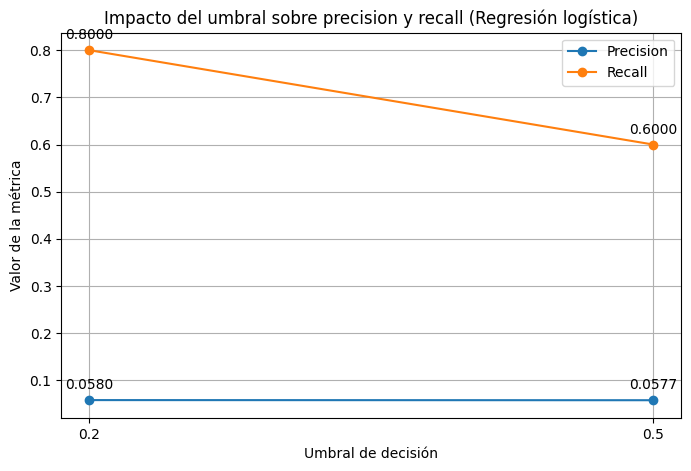

In [205]:
# Gráfica de precision y recall en función del umbral
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(tabla_umbral["Umbral"], tabla_umbral["Precision"], marker="o", label="Precision")
plt.plot(tabla_umbral["Umbral"], tabla_umbral["Recall"], marker="o", label="Recall")

for x, y in zip(tabla_umbral["Umbral"], tabla_umbral["Precision"]):
    plt.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
for x, y in zip(tabla_umbral["Umbral"], tabla_umbral["Recall"]):
    plt.annotate(f"{y:.4f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

plt.xlabel("Umbral de decisión")
plt.ylabel("Valor de la métrica")
plt.title("Impacto del umbral sobre precision y recall (Regresión logística)")
plt.xticks(umbrales)
plt.legend()
plt.grid(True)
plt.show()


**Interpretación:** al reducir el umbral de 0.50 a 0.20, el **recall aumenta** (se detectan más fraudes reales y bajan los falsos negativos), pero el **precision se mantiene bajo o cambia muy poco**, y los **falsos positivos aumentan**, ya que el modelo marca más transacciones como sospechosas en general. Esto ilustra el *trade-off* clásico entre precision y recall: bajar el umbral favorece la detección de fraude, pero incrementa la carga operativa de revisión sobre clientes legítimos. La elección de un umbral en producción dependería del costo relativo que la organización asigne a cada tipo de error (sección 18), decisión que corresponde al negocio y no únicamente al equipo de modelado.


## 1.20 - Seleccionar el modelo preliminar

Tal como lo exige la sección 13, **el conjunto de prueba no se utiliza para seleccionar el modelo**. Aunque en la sección 17 ya se evaluaron los modelos sobre `X_test`/`y_test` (para reportar sus métricas), la selección del modelo preliminar en esta sección se basa **exclusivamente en validación cruzada estratificada sobre el conjunto de entrenamiento** (`X_train`/`y_train`), manteniendo `X_test` reservado y sin usar para decidir.

Se compara la regresión logística contra el árbol de decisión mediante `StratifiedKFold` (5 folds), aplicando el **pipeline completo de preprocesamiento dentro de cada fold** (para evitar fuga de información entre folds) y calculando precision, recall, F1-score y ROC-AUC.


In [206]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Validación cruzada estratificada (solo sobre el conjunto de entrenamiento)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelo_lr_cv = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
modelo_dt_cv = DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=5)

# Pipelines completos: preprocesamiento + modelo, para que el preprocesador
# se reajuste dentro de cada fold y no haya fuga de información entre folds
pipeline_lr_cv = Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo_lr_cv)])
pipeline_dt_cv = Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo_dt_cv)])

scoring = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
}

resultados_lr_cv = cross_validate(pipeline_lr_cv, X_train, y_train, cv=cv, scoring=scoring)
resultados_dt_cv = cross_validate(pipeline_dt_cv, X_train, y_train, cv=cv, scoring=scoring)

resultados_validacion = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "Precision": [resultados_lr_cv["test_precision"].mean(), resultados_dt_cv["test_precision"].mean()],
    "Recall": [resultados_lr_cv["test_recall"].mean(), resultados_dt_cv["test_recall"].mean()],
    "F1-score": [resultados_lr_cv["test_f1"].mean(), resultados_dt_cv["test_f1"].mean()],
    "ROC-AUC": [resultados_lr_cv["test_roc_auc"].mean(), resultados_dt_cv["test_roc_auc"].mean()],
})

print("Resultados promedio de validación cruzada (5 folds, sobre entrenamiento):")
resultados_validacion.round(4)


Resultados promedio de validación cruzada (5 folds, sobre entrenamiento):


,Modelo,Precision,Recall,F1-score,ROC-AUC
0,Regresión logística,0.0404,0.3333,0.0720,0.8055
1,Árbol de decisión,0.0600,0.4667,0.1048,0.6715


In [207]:
# Matrices de confusión "out-of-fold" de la validación cruzada
# (predicciones sobre X_train cuando cada fila estuvo en el fold de validación;
#  y_test / X_test NO participan en ningún momento de este cálculo)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

pred_lr_cv = cross_val_predict(pipeline_lr_cv, X_train, y_train, cv=cv, method="predict")
pred_dt_cv = cross_val_predict(pipeline_dt_cv, X_train, y_train, cv=cv, method="predict")

cm_lr_cv = confusion_matrix(y_train, pred_lr_cv)
cm_dt_cv = confusion_matrix(y_train, pred_dt_cv)

vn_lr_cv, fp_lr_cv, fn_lr_cv, vp_lr_cv = cm_lr_cv.ravel()
vn_dt_cv, fp_dt_cv, fn_dt_cv, vp_dt_cv = cm_dt_cv.ravel()

errores_validacion = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "VN (validación)": [vn_lr_cv, vn_dt_cv],
    "FP (validación)": [fp_lr_cv, fp_dt_cv],
    "FN (validación)": [fn_lr_cv, fn_dt_cv],
    "VP (validación)": [vp_lr_cv, vp_dt_cv],
})

print("Matriz de errores acumulada durante la validación cruzada (sobre entrenamiento, no sobre prueba):")
errores_validacion


Matriz de errores acumulada durante la validación cruzada (sobre entrenamiento, no sobre prueba):


,Modelo,VN (validación),FP (validación),FN (validación),VP (validación)
0,Regresión logística,610,73,8,4
1,Árbol de decisión,604,79,7,5


**Nota importante:** la tabla anterior (errores de **validación cruzada**, calculados solo sobre `X_train`) es distinta de la tabla de errores de la sección 18 (errores sobre el conjunto de **prueba**, `X_test`). Ambas se reportan por separado y no deben combinarse: la de la sección 18 describe el desempeño ya observado en prueba, mientras que la de esta sección es la que efectivamente se usa para decidir el modelo preliminar, sin tocar el conjunto de prueba.


In [208]:
# Tabla de criterios cuantitativos: métricas promedio de validación cruzada + errores de validación cruzada
seleccion_modelo = resultados_validacion.copy()
seleccion_modelo["VN"] = [vn_lr_cv, vn_dt_cv]
seleccion_modelo["FP"] = [fp_lr_cv, fp_dt_cv]
seleccion_modelo["FN"] = [fn_lr_cv, fn_dt_cv]
seleccion_modelo["VP"] = [vp_lr_cv, vp_dt_cv]

print("Criterios cuantitativos para la selección del modelo (basados en validación cruzada):")
seleccion_modelo.round(4)


Criterios cuantitativos para la selección del modelo (basados en validación cruzada):


,Modelo,Precision,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
0,Regresión logística,0.0404,0.3333,0.0720,0.8055,610,73,8,4
1,Árbol de decisión,0.0600,0.4667,0.1048,0.6715,604,79,7,5


In [209]:
# Criterios cualitativos para la selección del modelo
criterios_cualitativos = pd.DataFrame({
    "Criterio": ["Interpretabilidad", "Complejidad", "Riesgo operativo", "Desempeño discriminativo", "Detección de fraudes"],
    "Regresión logística": [
        "Alta: permite analizar la influencia de cada variable sobre la probabilidad estimada",
        "Baja: modelo relativamente sencillo",
        "Menor cantidad de FP en validación",
        f"ROC-AUC promedio de {resultados_validacion.loc[0, 'ROC-AUC']:.4f}",
        f"Recall promedio de {resultados_validacion.loc[0, 'Recall']:.4f}",
    ],
    "Árbol de decisión": [
        "Alta: permite representar decisiones mediante reglas",
        "Baja/media: puede crecer en complejidad según su profundidad",
        "Mayor cantidad de FP en validación",
        f"ROC-AUC promedio de {resultados_validacion.loc[1, 'ROC-AUC']:.4f}",
        f"Recall promedio de {resultados_validacion.loc[1, 'Recall']:.4f}",
    ],
})

criterios_cualitativos


,Criterio,Regresión logística,Árbol de decisión
0,Interpretabilidad,Alta: permite analizar la influencia de cada v...,Alta: permite representar decisiones mediante ...
1,Complejidad,Baja: modelo relativamente sencillo,Baja/media: puede crecer en complejidad según ...
2,Riesgo operativo,Menor cantidad de FP en validación,Mayor cantidad de FP en validación
3,Desempeño discriminativo,ROC-AUC promedio de 0.8055,ROC-AUC promedio de 0.6715
4,Detección de fraudes,Recall promedio de 0.3333,Recall promedio de 0.4667


In [210]:
# Variabilidad de las métricas entre los 5 folds (soporta el carácter "preliminar" de la selección)
resumen_variabilidad = pd.DataFrame({
    "Modelo": ["Regresión logística", "Árbol de decisión"],
    "Precision media": [resultados_lr_cv["test_precision"].mean(), resultados_dt_cv["test_precision"].mean()],
    "Precision std": [resultados_lr_cv["test_precision"].std(), resultados_dt_cv["test_precision"].std()],
    "Recall medio": [resultados_lr_cv["test_recall"].mean(), resultados_dt_cv["test_recall"].mean()],
    "Recall std": [resultados_lr_cv["test_recall"].std(), resultados_dt_cv["test_recall"].std()],
    "F1 medio": [resultados_lr_cv["test_f1"].mean(), resultados_dt_cv["test_f1"].mean()],
    "F1 std": [resultados_lr_cv["test_f1"].std(), resultados_dt_cv["test_f1"].std()],
    "ROC-AUC medio": [resultados_lr_cv["test_roc_auc"].mean(), resultados_dt_cv["test_roc_auc"].mean()],
    "ROC-AUC std": [resultados_lr_cv["test_roc_auc"].std(), resultados_dt_cv["test_roc_auc"].std()],
})

resumen_variabilidad.round(4)


,Modelo,Precision media,Precision std,Recall medio,Recall std,F1 medio,F1 std,ROC-AUC medio,ROC-AUC std
0,Regresión logística,0.0404,0.0499,0.3333,0.4216,0.0720,0.0891,0.8055,0.1840
1,Árbol de decisión,0.0600,0.0396,0.4667,0.3232,0.1048,0.0687,0.6715,0.1509


In [211]:
# Detalle por fold (evidencia de la variabilidad reportada arriba)
metricas_folds = pd.DataFrame({
    "Fold": range(1, 6),
    "LR Precision": resultados_lr_cv["test_precision"],
    "LR Recall": resultados_lr_cv["test_recall"],
    "LR F1": resultados_lr_cv["test_f1"],
    "LR ROC-AUC": resultados_lr_cv["test_roc_auc"],
    "Árbol Precision": resultados_dt_cv["test_precision"],
    "Árbol Recall": resultados_dt_cv["test_recall"],
    "Árbol F1": resultados_dt_cv["test_f1"],
    "Árbol ROC-AUC": resultados_dt_cv["test_roc_auc"],
})

metricas_folds.round(4)


,Fold,LR Precision,LR Recall,LR F1,LR ROC-AUC,Árbol Precision,Árbol Recall,Árbol F1,Árbol ROC-AUC
0,1,0.1111,1.0000,0.20,1.0000,0.1053,1.0000,0.1905,0.9288
1,2,0.0000,0.0000,0.00,0.4599,0.0357,0.5000,0.0667,0.6369
2,3,0.0000,0.0000,0.00,0.8029,0.1000,0.5000,0.1667,0.7026
3,4,0.0909,0.6667,0.16,0.8922,0.0588,0.3333,0.1000,0.6262
4,5,0.0000,0.0000,0.00,0.8725,0.0000,0.0000,0.0000,0.4632


In [212]:
# Comprobación final: el conjunto de prueba conserva su proporción de clases
# y no fue tocado por la validación cruzada anterior (que solo usó X_train/y_train)
print("Distribución en entrenamiento (usada en la validación cruzada):")
print(y_train.value_counts())
print(f"Proporción de fraude en entrenamiento: {y_train.mean():.4f}")
print()
print("Distribución en prueba (reservada, no utilizada para seleccionar el modelo):")
print(y_test.value_counts())
print(f"Proporción de fraude en prueba: {y_test.mean():.4f}")


Distribución en entrenamiento (usada en la validación cruzada):
fraude
0    683
1     12
Name: count, dtype: int64
Proporción de fraude en entrenamiento: 0.0173

Distribución en prueba (reservada, no utilizada para seleccionar el modelo):
fraude
0    294
1      5
Name: count, dtype: int64
Proporción de fraude en prueba: 0.0167


### 1.21 - Selección del modelo preliminar

A partir de los resultados de validación cruzada, se compara la regresión logística contra el árbol de decisión considerando precision, recall, F1-score, ROC-AUC, la cantidad de falsos positivos/negativos en validación, e interpretabilidad, complejidad y riesgo operativo.

El árbol de decisión presenta mejores valores promedio de precision, recall y F1-score en validación cruzada, detectando en promedio una mayor proporción de los casos fraudulentos. Sin embargo, la regresión logística presenta una ventaja importante en **ROC-AUC**, lo que indica una mejor capacidad general para discriminar entre operaciones legítimas y fraudulentas a lo largo de todos los posibles umbrales, y además acumula menos falsos positivos durante la validación cruzada, lo que representa una menor carga operativa para el equipo de revisión.

Ambos modelos son interpretables (coeficientes en el caso de la regresión logística, reglas de decisión en el caso del árbol) y de complejidad relativamente baja. Considerando conjuntamente el desempeño discriminativo (ROC-AUC), el número de falsos positivos y la interpretabilidad, se selecciona la **regresión logística como modelo preliminar**.

Esta selección se considera **preliminar** debido al fuerte desbalance de clases presente en los datos: el conjunto de entrenamiento contiene muy pocos casos fraudulentos, por lo que pequeñas variaciones en la cantidad de fraudes detectados por fold pueden producir cambios importantes en precision, recall y F1-score (ver variabilidad entre folds arriba). El modelo seleccionado deberá evaluarse formalmente sobre el conjunto de prueba reservado (`X_test`/`y_test`) en una etapa posterior, ya fuera de la selección del modelo.


In [213]:
# Modelo seleccionado preliminarmente
modelo_preliminar = "Regresión logística"

print(f"Modelo preliminar seleccionado: {modelo_preliminar}")
print("Motivo principal: mejor ROC-AUC en validación cruzada y menor cantidad de falsos positivos en validación,")
print("manteniendo una interpretabilidad y complejidad adecuadas para el contexto de negocio.")


Modelo preliminar seleccionado: Regresión logística
Motivo principal: mejor ROC-AUC en validación cruzada y menor cantidad de falsos positivos en validación,
manteniendo una interpretabilidad y complejidad adecuadas para el contexto de negocio.


# Detección de fraude en comercio electrónico
### Seguimiento del proyecto — Etapa final: modelos adicionales, ensambles, optimización, agrupamiento y redes neuronales

**Contexto asignado:** Opción 2 — Detección de fraude en comercio electrónico
**Dataset:** `02_fraude_ecommerce.csv`
**Tipo de problema:** Clasificación binaria supervisada (con una exploración no supervisada complementaria)
**Alcance de esta entrega:** Secciones 2.0 a 2.13 (recuperación del modelo preliminar, modelos adicionales, método de ensamble, optimización, dimensionalidad, agrupamiento, red neuronal, comparación general y selección del modelo final). Las secciones 1.1 a 1.21 corresponden a la primera etapa.

**Integrantes del equipo:** *(completar)*
**Fecha:** *(completar)*


## 2.0 - Reanudación del proyecto

En la primera etapa (secciones 1.1 a 1.21) se definió el problema de clasificación binaria, se exploró y diagnosticó la calidad de los datos, se separaron las variables predictoras y la variable objetivo, se diseñó una partición 70/30 estratificada, se construyó un pipeline de preprocesamiento reproducible, se estableció un baseline (`DummyClassifier`) y se entrenaron dos modelos iniciales (regresión logística y árbol de decisión). Como resultado, se seleccionó de forma **preliminar** la **regresión logística**.

En esta segunda etapa se lleva el proyecto a una fase experimental más completa, con el objetivo de determinar **qué estrategia ofrece mejores resultados** para detectar fraude en la tienda en línea:

- Recuperar el modelo preliminar (2.1) y entrenar cinco modelos adicionales de familias distintas (2.2).
- Aplicar un método de ensamble (2.3), optimizar un modelo (2.4) y analizar la dimensionalidad de los datos (2.5).
- Explorar grupos naturales con aprendizaje no supervisado (2.6 y 2.7).
- Construir y evaluar una red neuronal artificial (2.8 a 2.10).
- Comparar todos los modelos (2.11 y 2.12) y seleccionar el modelo final (2.13).

Se sigue trabajando con el **mismo dataset** (`02_fraude_ecommerce.csv`), la **misma partición** (70/30 estratificada, `random_state=42`) y el **mismo pipeline de preprocesamiento** de las secciones 1.12 a 1.14, de modo que la comparación entre modelos sea justa. Por eso esta etapa **no vuelve a cargar ni a limpiar los datos**: reutiliza los objetos ya creados en este notebook (`X_train_procesado`, `X_test_procesado`, `y_train`, `y_test`, `preprocesador`, `nombres_finales`), por lo que las celdas deben ejecutarse en orden, a continuación de la primera etapa.

**Aclaración importante:** el conjunto de prueba contiene solo **5 transacciones fraudulentas** (y el de entrenamiento 12), por lo que una diferencia de un solo caso modifica el recall en 20 puntos porcentuales. Todos los resultados de esta etapa deben leerse con esa cautela.


In [214]:
# Verificación de los objetos heredados de la etapa 1 (misma partición y mismo pipeline)
print("Entrenamiento:", X_train_procesado.shape, "| fraudes:", int(y_train.sum()))
print("Prueba:       ", X_test_procesado.shape, "| fraudes:", int(y_test.sum()))
print("Número de características después del preprocesamiento:", len(nombres_finales))

Entrenamiento: (695, 21) | fraudes: 12
Prueba:        (299, 21) | fraudes: 5
Número de características después del preprocesamiento: 21


## 2.1 - Recuperar el modelo preliminar

Se recuperan los resultados de la primera etapa (baseline, regresión logística y árbol de decisión) directamente de los modelos ya entrenados y evaluados en las secciones 1.15 a 1.17, **sin volver a entrenarlos**, sobre el mismo conjunto de prueba. Además de las cinco métricas principales, se incluyen los conteos de la matriz de confusión (VN, FP, FN, VP), que se usarán en la comparación final.

En esta celda también se define la función auxiliar `resumen_metricas`, con la que se calcularán las métricas de todos los modelos de esta etapa de la misma manera, y los diccionarios `predicciones_test` y `probabilidades_test`, donde se guardarán las predicciones de cada modelo para reutilizarlas en la comparación final.


In [215]:
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# Función auxiliar: métricas y conteos de la matriz de confusión de cualquier modelo (conjunto de prueba)
def resumen_metricas(nombre, y_real, y_pred, y_proba):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred).ravel()
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1-score": f1_score(y_real, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_real, y_proba),
        "VN": vn, "FP": fp, "FN": fn, "VP": vp,
    }

# Predicciones y probabilidades (conjunto de prueba) de los modelos de la primera etapa,
# tomadas de las secciones 1.15 a 1.17 (no se vuelven a entrenar)
predicciones_test = {
    "Baseline (Dummy)": y_pred_baseline,
    "Regresión logística": y_pred_lr,
    "Árbol de decisión": y_pred_dt,
}
probabilidades_test = {
    "Baseline (Dummy)": y_proba_baseline,
    "Regresión logística": y_proba_lr,
    "Árbol de decisión": y_proba_dt,
}

# Diccionario donde se irán guardando las métricas de TODOS los modelos de la etapa final
resultados_por_modelo = {
    nombre: resumen_metricas(nombre, y_test, predicciones_test[nombre], probabilidades_test[nombre])
    for nombre in predicciones_test
}

# Tabla resumen del punto 1 (solo las métricas solicitadas)
tabla_preliminar = pd.DataFrame(resultados_por_modelo.values())[
    ["Modelo", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
]
tabla_preliminar.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline (Dummy),0.9732,0.0000,0.0,0.0000,0.4949
1,Regresión logística,0.8294,0.0577,0.6,0.1053,0.8619
2,Árbol de decisión,0.8562,0.0476,0.4,0.0851,0.6350


**Modelo preliminar seleccionado: regresión logística.**

**Motivo:** en la sección 1.21 se eligió mediante **validación cruzada estratificada sobre el entrenamiento** (sin usar el conjunto de prueba), por tener mejor ROC-AUC (0.8055 frente a 0.6715), menos falsos positivos en validación (73 frente a 79) y una interpretabilidad alta (coeficientes).

**Interpretación:** los resultados sobre el conjunto de prueba confirman esa elección. La regresión logística obtiene el mejor ROC-AUC de los tres modelos (0.8619) y detecta 3 de los 5 fraudes (recall = 0.60), a costa de 49 falsos positivos. El árbol de decisión detecta 2 fraudes con 40 falsos positivos y un ROC-AUC de solo 0.6350. El baseline alcanza el accuracy más alto (0.9732) únicamente porque casi siempre predice "legítima": no detecta ningún fraude (recall = 0) y su ROC-AUC (0.4949) equivale al azar. Estos resultados son el punto de referencia que los modelos de esta etapa deben superar.


## 2.2 - Entrenar modelos adicionales de clasificación

Se amplía la experimentación con **cinco modelos adicionales** de familias distintas a las de la primera etapa (regresión logística: modelo lineal; árbol de decisión: reglas), sin repetir ninguno de ellos:

| Modelo | Familia | Configuración | Justificación |
|---|---|---|---|
| Random Forest | Ensamble (bagging) | `n_estimators=100`, `class_weight="balanced_subsample"`, `random_state=42` | Promedia muchos árboles y reduce la varianza de un árbol individual; `balanced_subsample` compensa el desbalance en cada submuestra |
| Gradient Boosting | Ensamble (boosting) | `n_estimators=100`, `learning_rate=0.1`, `random_state=42` | Construye árboles en secuencia, cada uno corrige los errores del anterior; suele ser muy competitivo en datos tabulares. No admite `class_weight` |
| SVM (RBF) | Márgenes / kernels | `kernel="rbf"`, `C=1.0`, `class_weight="balanced"`, `probability=True` | Busca la frontera de mayor margen y el kernel RBF captura relaciones no lineales; `probability=True` permite calcular el ROC-AUC |
| KNN | Basado en instancias | `n_neighbors=5`, `weights="distance"` | Clasifica según las transacciones más parecidas; no supone una forma para la frontera. No admite `class_weight` |
| Naive Bayes | Probabilístico | `GaussianNB()` (parámetros por defecto) | Modelo rápido que sirve como referencia probabilística; supone independencia entre variables y distribución normal |

Para cada modelo se sigue la secuencia **Modelo → Configuración → Entrenamiento → Predicción → Métricas → Interpretación**. Todos se entrenan solo con `X_train_procesado` / `y_train` y se evalúan sobre `X_test_procesado` / `y_test` (misma partición y mismo preprocesamiento que en la primera etapa), con el umbral de decisión estándar de 0.50.


In [216]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# 1. Configuración de los cinco modelos adicionales
modelos_adicionales = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample", random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.1, random_state=42),
    "SVM (RBF)": SVC(
        kernel="rbf", C=1.0, class_weight="balanced", probability=True, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance"),
    "Naive Bayes": GaussianNB(),
}

# 2. Entrenamiento -> predicción -> métricas (misma partición y mismo preprocesamiento)
modelos_entrenados = {}
for nombre, modelo in modelos_adicionales.items():
    modelo.fit(X_train_procesado, y_train)                        # entrenamiento (solo con entrenamiento)
    y_pred_modelo = modelo.predict(X_test_procesado)              # predicción (umbral 0.50)
    y_proba_modelo = modelo.predict_proba(X_test_procesado)[:, 1] # probabilidad de la clase positiva

    modelos_entrenados[nombre] = modelo
    predicciones_test[nombre] = y_pred_modelo
    probabilidades_test[nombre] = y_proba_modelo
    resultados_por_modelo[nombre] = resumen_metricas(nombre, y_test, y_pred_modelo, y_proba_modelo)

tabla_adicionales = pd.DataFrame([resultados_por_modelo[n] for n in modelos_adicionales])
tabla_adicionales.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
0,Random Forest,0.9833,0.0000,0.0,0.0000,0.8170,294,0,5,0
1,Gradient Boosting,0.9699,0.0000,0.0,0.0000,0.8265,290,4,5,0
2,SVM (RBF),0.9431,0.0000,0.0,0.0000,0.8381,282,12,5,0
3,KNN,0.9833,0.0000,0.0,0.0000,0.6541,294,0,5,0
4,Naive Bayes,0.1873,0.0163,0.8,0.0319,0.6316,52,242,1,4


**Interpretación por modelo:**

- **Random Forest:** accuracy 0.9833 y ROC-AUC 0.8170, pero **0 fraudes detectados** (0 FP y 5 FN). Ordena razonablemente las transacciones, pero ninguna probabilidad llega a 0.50 (se analiza en 2.3), por lo que con el umbral por defecto no genera alertas.
- **Gradient Boosting:** ROC-AUC 0.8265, con 4 FP y 5 FN (VP = 0). Las 4 alertas que emite son falsas alarmas y no detecta ningún fraude.
- **SVM (RBF):** el mayor ROC-AUC de los cinco modelos (0.8381), pero también con VP = 0 y 12 FP.
- **KNN:** VP = 0 y 0 FP; ROC-AUC de 0.6541. Con solo 12 fraudes en entrenamiento, los vecinos más cercanos de casi cualquier transacción son legítimos, por lo que casi nunca vota por fraude.
- **Naive Bayes:** el recall más alto (0.80; detecta 4 de 5 fraudes), pero con **242 falsos positivos**: marca como sospechosas 246 de 299 transacciones (accuracy de 0.1873, ROC-AUC de 0.6316). Es inviable operativamente. Una posible causa es que supone distribuciones normales en variables que, tras el One-Hot Encoding, son binarias.

**Interpretación general:** los accuracy altos de Random Forest y KNN (0.9833) son un artefacto del desbalance, igual que en el baseline. Con el umbral de 0.50, Random Forest, Gradient Boosting, SVM y KNN **no detectan ningún fraude** y Naive Bayes detecta 4 pero con una carga de revisión inaceptable. Ninguno supera a la regresión logística, que sigue siendo el único modelo con recall de 0.60 y ROC-AUC de 0.86 con falsas alarmas manejables. Que SVM, Gradient Boosting y Random Forest tengan un ROC-AUC superior a 0.81 indica que sí ordenan las transacciones por riesgo, pero el umbral de 0.50 no convierte esas probabilidades en alertas; este punto se retoma en 2.4 y 2.13.


### Verificación de los valores en cero (precision, recall y F1-score)

En la tabla anterior, Random Forest, Gradient Boosting, SVM y KNN muestran precision, recall y F1-score iguales a 0. Para comprobar que no se trata de un error de cálculo, la siguiente celda desglosa, para esos cuatro modelos, cuántas alertas emitió cada uno, cuántas fueron correctas, con qué probabilidad máxima puntuó a los fraudes reales y en qué posición del ordenamiento por riesgo quedaron los 5 fraudes de prueba (posición 1 = la transacción que el modelo considera más riesgosa de las 299).


In [217]:
# Verificación de los valores en cero (umbral 0.50, conjunto de prueba)
filas_verificacion = []
for nombre in ["Random Forest", "Gradient Boosting", "SVM (RBF)", "KNN"]:
    pred = predicciones_test[nombre]
    proba = probabilidades_test[nombre]
    es_fraude = (y_test.values == 1)
    alertas = int(pred.sum())
    vp = int(((pred == 1) & es_fraude).sum())
    posicion = (-proba).argsort().argsort() + 1        # 1 = transacción con mayor riesgo estimado
    filas_verificacion.append({
        "Modelo": nombre,
        "Alertas emitidas": alertas,
        "Precision = VP / alertas": f"{vp} / {alertas}",
        "Recall = VP / fraudes reales": f"{vp} / {int(es_fraude.sum())}",
        "Prob. máxima en un fraude real": proba[es_fraude].max(),
        "Prob. máxima en toda la prueba": proba.max(),
        "Posición de los 5 fraudes (de 299)": sorted(int(p) for p in posicion[es_fraude]),
        "Fraudes entre el 10% más riesgoso": int((posicion[es_fraude] <= 30).sum()),
    })
pd.DataFrame(filas_verificacion).round(3)

,Modelo,Alertas emitidas,Precision = VP / alertas,Recall = VP / fraudes reales,Prob. máxima en un fraude real,Prob. máxima en toda la prueba,Posición de los 5 fraudes (de 299),Fraudes entre el 10% más riesgoso
0,Random Forest,0,0 / 0,0 / 5,0.100,0.300,"[12, 32, 54, 81, 119]",1
1,Gradient Boosting,4,0 / 4,0 / 5,0.381,0.998,"[5, 27, 53, 71, 114]",2
2,SVM (RBF),12,0 / 12,0 / 5,0.068,0.154,"[15, 39, 50, 69, 80]",1
3,KNN,0,0 / 0,0 / 5,0.213,0.419,"[7, 23, 43, 169, 212]",2


**Interpretación:** los ceros son correctos y tienen una explicación directa en la definición de las métricas:

- **Recall = VP / (VP + FN) = 0 / 5 en los cuatro modelos:** ninguno detectó alguno de los 5 fraudes reales (los 5 son falsos negativos).
- **Precision = VP / (VP + FP) = 0:** en Gradient Boosting (0 de 4 alertas) y SVM (0 de 12 alertas) es un cero real, porque todas las alertas que emitieron fueron falsas. En Random Forest y KNN **no emitieron ninguna alerta**, de modo que la precision es 0 / 0, es decir, indefinida; `scikit-learn` la reporta como 0 porque en `resumen_metricas` se indicó `zero_division=0`. En esos dos casos el 0 significa "no hubo alertas", no "todas las alertas fueron falsas".
- **F1-score = 0:** es la media armónica de precision y recall y vale 0 en cuanto alguno de los dos es 0.

**¿Por qué no detectan ningún fraude?** Con el umbral de 0.50, un fraude se detecta solo si el modelo le asigna una probabilidad de al menos 0.50. La probabilidad máxima que cada modelo asignó a un fraude real fue de 0.100 en Random Forest, 0.381 en Gradient Boosting, 0.068 en SVM y 0.213 en KNN: ninguna alcanza el umbral. Con solo 12 fraudes (1.7%) en el entrenamiento, estos modelos aprenden a asignar probabilidades bajas a casi cualquier transacción, y `class_weight` (que solo tienen Random Forest y SVM) no basta para revertirlo con tan pocos ejemplos.

**Los modelos no están "a ciegas":** los fraudes reales quedan en posiciones altas del ordenamiento por riesgo (por ejemplo, Gradient Boosting y KNN colocan 2 de los 5 fraudes dentro del 10% de transacciones más riesgosas, y Random Forest y SVM colocan 1; al azar se esperaría 0.5), lo que es consistente con sus ROC-AUC de entre 0.65 y 0.84. Pero ese ordenamiento no se convierte en alertas con el umbral de 0.50, y el ordenamiento es imperfecto: en todos los casos hay fraudes que quedan muy lejos de los primeros lugares.

**Nota sobre el SVM:** aunque su probabilidad máxima en toda la prueba es 0.154 (menor a 0.50), emitió 12 alertas. Esto ocurre porque, en `SVC`, las etiquetas de `predict()` se obtienen de la frontera de decisión del propio SVM, mientras que `predict_proba()` proviene de una calibración interna distinta (Platt scaling) y ambas pueden no coincidir. Las alertas se toman de `predict()`, y las probabilidades solo se usan para calcular el ROC-AUC.

**Conclusión:** los valores en cero no son un error, sino el comportamiento real de estos modelos con el umbral estándar y muy pocos fraudes de ejemplo. Por eso sus accuracy (entre 0.94 y 0.98) engañan y por eso, pese a su buen ROC-AUC, no son útiles para detectar fraude sin un ajuste adicional del umbral.


## 2.3 - Aplicar un método de ensamble (Random Forest)

Se selecciona **Random Forest** (`RandomForestClassifier`, ya entrenado en la sección 2.2) como método de ensamble. Gradient Boosting, que también pertenece a la familia de ensambles, se conserva como modelo comparativo.

**¿Cómo funciona el método seleccionado?**
Random Forest es un ensamble de tipo **bagging**: construye muchos árboles de decisión, cada uno entrenado con una submuestra aleatoria con reemplazo (*bootstrap*) de las transacciones de entrenamiento y considerando solo un subconjunto aleatorio de variables en cada división. Para clasificar una transacción, cada árbol emite su predicción y el bosque **promedia** los resultados. En este proyecto el bosque se compone de 100 árboles.

**¿Qué ventaja tiene frente a un modelo individual?**
Un árbol individual es inestable y tiende a memorizar el entrenamiento (varianza alta): un cambio pequeño en los datos puede producir un árbol muy distinto. Al promediar muchos árboles diferentes, sus errores se compensan, con lo que se **reduce la varianza y el sobreajuste** y se obtienen probabilidades más estables para ordenar las transacciones por riesgo.

**¿Qué hiperparámetros principales se utilizaron?**
- `n_estimators=100`: número de árboles del bosque.
- `class_weight="balanced_subsample"`: da más peso a la clase de fraude dentro de cada submuestra bootstrap, para compensar el desbalance documentado en la sección 1.11.
- `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `max_features="sqrt"`: valores por defecto (árboles sin límite de profundidad).
- `random_state=42`: reproducibilidad.

Para responder si mejoró los resultados y qué ocurrió con los errores, se compara el ensamble contra el árbol individual (sección 1.16) y contra el modelo preliminar (regresión logística), y se revisan las probabilidades que el bosque asignó a los fraudes reales.


In [218]:
# Probabilidades que Random Forest asigna a los fraudes reales del conjunto de prueba
proba_rf = probabilidades_test["Random Forest"]
print("Probabilidad asignada por Random Forest a cada uno de los 5 fraudes reales:")
print(np.round(proba_rf[y_test.values == 1], 3))
print(f"\nProbabilidad máxima asignada a cualquier transacción de prueba: {proba_rf.max():.3f}")
print(f"Transacciones con probabilidad >= 0.50 (marcadas como fraude): {int((proba_rf >= 0.50).sum())}")

# Comparación del ensamble contra el árbol individual y contra el modelo preliminar
tabla_ensamble = pd.DataFrame([resultados_por_modelo[n]
                               for n in ["Árbol de decisión", "Regresión logística", "Random Forest"]])
tabla_ensamble.round(4)

Probabilidad asignada por Random Forest a cada uno de los 5 fraudes reales:
[0.03 0.1  0.01 0.02 0.05]

Probabilidad máxima asignada a cualquier transacción de prueba: 0.300
Transacciones con probabilidad >= 0.50 (marcadas como fraude): 0


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
0,Árbol de decisión,0.8562,0.0476,0.4,0.0851,0.6350,254,40,3,2
1,Regresión logística,0.8294,0.0577,0.6,0.1053,0.8619,245,49,2,3
2,Random Forest,0.9833,0.0000,0.0,0.0000,0.8170,294,0,5,0


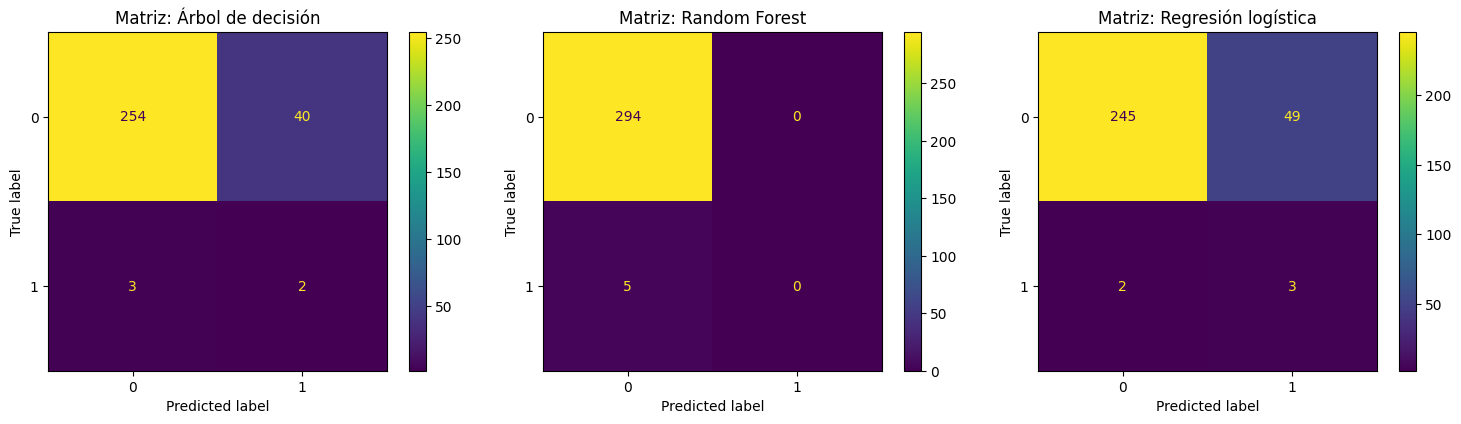

In [219]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Matrices de confusión: árbol individual vs. ensamble vs. modelo preliminar
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for eje, nombre in zip(axes, ["Árbol de decisión", "Random Forest", "Regresión logística"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones_test[nombre], ax=eje)
    eje.set_title(f"Matriz: {nombre}")
plt.tight_layout()
plt.show()

**Interpretación:**

- **¿Mejoró los resultados respecto al modelo preliminar?** No. Random Forest tiene el accuracy más alto (0.9833) y un ROC-AUC de 0.8170, pero su recall es 0: no detecta ninguno de los 5 fraudes, mientras que la regresión logística detecta 3 (recall = 0.60) con un ROC-AUC mayor (0.8619).
- **¿Qué ocurrió con los falsos positivos y falsos negativos?** El bosque tiene **0 falsos positivos** (frente a 49 de la regresión logística), pero **5 falsos negativos** (frente a 2). Eliminó las falsas alarmas a costa de dejar pasar todos los fraudes, que es justamente el error más costoso en este contexto (sección 1.18).
- **¿Por qué ocurre?** Las probabilidades que asigna a los 5 fraudes reales van de 0.01 a 0.10, y la máxima probabilidad que asigna a cualquier transacción de prueba es 0.30: ninguna alcanza el umbral de 0.50. Una explicación probable es que, con solo 12 fraudes en entrenamiento, la mayoría de los árboles clasifica casi todo como legítimo y al promediar sus resultados la probabilidad de fraude se diluye.
- **Frente al árbol individual** sí hay una mejora clara en la capacidad de ordenar los casos por riesgo (ROC-AUC de 0.6350 a 0.8170), que es la ventaja esperada del promedio de árboles. Sin embargo, esa mejora no se traduce en detecciones con el umbral de 0.50 (el recall baja de 0.40 a 0).

**Conclusión:** el ensamble mejora la calidad del ordenamiento respecto al árbol individual, pero **no supera al modelo preliminar en la detección de fraude** con su configuración inicial. En la sección 2.4 se prueba si ajustar sus hiperparámetros modifica este resultado.


## 2.4 - Optimizar un modelo

Se selecciona **Random Forest** para la búsqueda de hiperparámetros: es el ensamble de la sección 2.3, su ROC-AUC en prueba ya era alto (0.8170) aunque no lograba convertirlo en detecciones, y sus hiperparámetros (profundidad, tamaño mínimo de hojas, ponderación de clases) permiten regularizarlo, algo conveniente con solo 12 fraudes en entrenamiento.

Se utiliza `RandomizedSearchCV`, que evalúa una muestra aleatoria del espacio de búsqueda y es más eficiente que probar todas las combinaciones con `GridSearchCV`. La búsqueda se hace con validación cruzada estratificada de **3 folds** sobre el conjunto de entrenamiento (así cada fold conserva 4 fraudes) y con **ROC-AUC** como métrica a optimizar, porque no depende del umbral de decisión.

| Elemento | Configuración |
|---|---|
| Configuración original | `n_estimators=100`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `class_weight="balanced_subsample"` |
| Espacio de búsqueda | `n_estimators`: [50, 100, 150] · `max_depth`: [3, 5, 8, None] · `min_samples_split`: [2, 5, 10] · `min_samples_leaf`: [1, 2, 4] · `class_weight`: ["balanced", "balanced_subsample"] (216 combinaciones) |
| Búsqueda | `RandomizedSearchCV`: 12 combinaciones, 3 folds estratificados, `scoring="roc_auc"`, `random_state=42` |
| Datos utilizados | Solo entrenamiento; el conjunto de prueba no participa en la búsqueda |

**Nota:** la búsqueda se realiza sobre `X_train_procesado`, es decir, con el preprocesamiento ajustado con todo el entrenamiento. Con transformaciones simples (mediana, estandarización y One-Hot) el efecto de esto es mínimo; en la validación cruzada de la sección 2.13, en cambio, el preprocesamiento se reajusta dentro de cada fold.


In [220]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score

# Validación cruzada de 3 folds estratificados (solo sobre entrenamiento)
cv_busqueda = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Configuración original (sección 2.2): ROC-AUC en validación cruzada como referencia
rf_original = modelos_entrenados["Random Forest"]
auc_cv_original = cross_val_score(clone(rf_original), X_train_procesado, y_train,
                                  cv=cv_busqueda, scoring="roc_auc")
print(f"Configuración original -> ROC-AUC en validación cruzada: {auc_cv_original.mean():.4f}")

# 2. Espacio de búsqueda
distribucion_parametros = {
    "n_estimators": [50, 100, 150],
    "max_depth": [3, 5, 8, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced", "balanced_subsample"],
}

# 3. Búsqueda aleatoria de hiperparámetros (12 combinaciones de las 216 posibles)
busqueda = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=distribucion_parametros,
    n_iter=12,
    scoring="roc_auc",
    cv=cv_busqueda,
    random_state=42,
    n_jobs=-1,
)
busqueda.fit(X_train_procesado, y_train)

print("\nMejores hiperparámetros encontrados:")
print(busqueda.best_params_)
print(f"Mejor ROC-AUC en validación cruzada: {busqueda.best_score_:.4f}")

# 4. Las 5 mejores combinaciones exploradas
resultados_busqueda = pd.DataFrame(busqueda.cv_results_)[
    ["params", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score").head(5)
resultados_busqueda.round(4)

Configuración original -> ROC-AUC en validación cruzada: 0.8016

Mejores hiperparámetros encontrados:
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': 3, 'class_weight': 'balanced'}
Mejor ROC-AUC en validación cruzada: 0.8546


,params,mean_test_score,std_test_score,rank_test_score
4,"{'n_estimators': 50, 'min_samples_split': 10, ...",0.8546,0.0415,1
8,"{'n_estimators': 100, 'min_samples_split': 10,...",0.8518,0.0271,2
1,"{'n_estimators': 50, 'min_samples_split': 10, ...",0.8459,0.0241,3
7,"{'n_estimators': 100, 'min_samples_split': 2, ...",0.8364,0.0150,4
6,"{'n_estimators': 150, 'min_samples_split': 2, ...",0.8345,0.0123,5


In [221]:
# Desempeño del modelo optimizado en el conjunto de prueba
rf_optimizado = busqueda.best_estimator_        # ya reajustado con todo el entrenamiento (refit=True)
y_pred_rfo = rf_optimizado.predict(X_test_procesado)
y_proba_rfo = rf_optimizado.predict_proba(X_test_procesado)[:, 1]

predicciones_test["RF optimizado"] = y_pred_rfo
probabilidades_test["RF optimizado"] = y_proba_rfo
resultados_por_modelo["RF optimizado"] = resumen_metricas("RF optimizado", y_test, y_pred_rfo, y_proba_rfo)

# Configuración original -> búsqueda -> mejores parámetros -> nuevo desempeño
tabla_optimizacion = pd.DataFrame([resultados_por_modelo["Random Forest"],
                                   resultados_por_modelo["RF optimizado"]])
tabla_optimizacion.insert(1, "ROC-AUC validación cruzada", [auc_cv_original.mean(), busqueda.best_score_])
tabla_optimizacion["Modelo"] = ["RF original", "RF optimizado"]
tabla_optimizacion.round(4)

,Modelo,ROC-AUC validación cruzada,Accuracy,Precision,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
0,RF original,0.8016,0.9833,0.0000,0.0,0.0000,0.8170,294,0,5,0
1,RF optimizado,0.8546,0.9699,0.1667,0.2,0.1818,0.8048,289,5,4,1


**Interpretación:**

**Resumen: configuración original → búsqueda → mejores parámetros → nuevo desempeño**

| Etapa | Resultado |
|---|---|
| Configuración original | ROC-AUC en validación cruzada = 0.8016. En prueba: ROC-AUC 0.8170, recall 0.00, F1-score 0.0000, FP 0, FN 5 |
| Búsqueda | 12 combinaciones de 216 posibles; la mejor obtiene un ROC-AUC en validación cruzada de 0.8546 (desviación 0.0415) |
| Mejores parámetros | `n_estimators=50`, `max_depth=3`, `min_samples_split=10`, `min_samples_leaf=2`, `class_weight="balanced"` |
| Nuevo desempeño (prueba) | ROC-AUC 0.8048, precision 0.1667, recall 0.20, F1-score 0.1818, FP 5, FN 4 |

Los mejores parámetros describen un bosque más pequeño y con **árboles poco profundos y más regularizados** que el original, que no limitaba la profundidad.

**¿La optimización realmente mejoró el modelo?** Solo de forma parcial y poco concluyente:
- En **validación cruzada**, el ROC-AUC subió de 0.8016 a 0.8546. Sin embargo, esa es la métrica que la búsqueda maximizó (calculada sobre folds con solo 4 fraudes), por lo que es una estimación optimista; además, la segunda mejor combinación obtuvo 0.8518, prácticamente empatada.
- En el **conjunto de prueba**, el ROC-AUC bajó ligeramente (0.8170 → 0.8048, una diferencia que está dentro del ruido con tan pocos fraudes), pero el modelo pasó de no detectar ningún fraude a detectar 1 de 5 (recall de 0 a 0.20 y F1-score de 0 a 0.1818), a cambio de 5 falsos positivos.
- Ese único fraude adicional es una diferencia de **un solo caso**, insuficiente para afirmar una mejora robusta. Además, el modelo optimizado sigue por debajo del modelo preliminar (recall 0.60 y ROC-AUC 0.8619).

**Conclusión:** la optimización volvió al Random Forest **más útil operativamente** (de ninguna detección a una) al regularizarlo, pero no cambió la conclusión de la sección 2.3: con los datos disponibles no supera a la regresión logística.


## 2.5 - Analizar la dimensionalidad de los datos

Tras el preprocesamiento, las 11 variables originales se convierten en **21 características** (6 numéricas y 15 columnas binarias del One-Hot Encoding, sección 1.14) para solo 12 fraudes en entrenamiento. Cuando hay muchas características y muy pocos casos positivos, aumenta el riesgo de que el modelo aprenda ruido, por lo que conviene revisar si algunas aportan poco.

**Técnica seleccionada:** importancia de características con selección mediante `SelectFromModel`. Se calcula la importancia de cada característica con el Random Forest optimizado (sección 2.4) y se conservan las que tienen una importancia igual o mayor a la **mediana**.

**Justificación:** es una técnica apropiada para este proyecto porque (1) conserva las características originales y sus nombres, lo que mantiene la interpretabilidad y permite explicar al equipo de fraude por qué se marcó una transacción, y (2) utiliza la variable objetivo para medir la utilidad de cada característica. Se descarta PCA porque es no supervisado (retiene la mayor varianza, no necesariamente la información que distingue al fraude, algo riesgoso con solo 12 fraudes), mezclaría variables numéricas con columnas binarias del One-Hot y sus componentes no tienen significado de negocio.

Se compara el modelo original (Random Forest optimizado con 21 características) contra el modelo con las características seleccionadas en cuanto a desempeño, número de características, tiempo de entrenamiento e interpretabilidad. El selector se ajusta únicamente con el conjunto de entrenamiento.


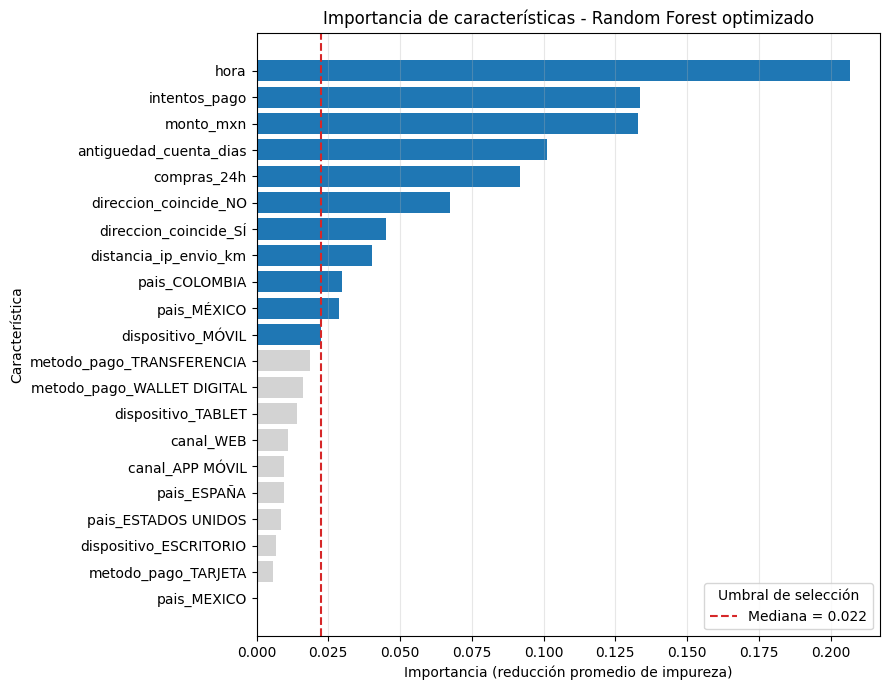

,Característica,Importancia,Importancia acumulada
0,hora,0.2069,0.2069
1,intentos_pago,0.1335,0.3403
2,monto_mxn,0.1328,0.4731
3,antiguedad_cuenta_dias,0.1011,0.5742
4,compras_24h,0.0919,0.6661
5,direccion_coincide_NO,0.0674,0.7335
6,direccion_coincide_SÍ,0.0452,0.7787
7,distancia_ip_envio_km,0.0402,0.8189
8,pais_COLOMBIA,0.0298,0.8487
9,pais_MÉXICO,0.0288,0.8775


In [222]:
import matplotlib.pyplot as plt

# Importancia de las características según el Random Forest optimizado
importancias = pd.DataFrame({
    "Característica": nombres_finales,
    "Importancia": rf_optimizado.feature_importances_,
}).sort_values("Importancia", ascending=False).reset_index(drop=True)
importancias["Importancia acumulada"] = importancias["Importancia"].cumsum()

mediana_importancia = importancias["Importancia"].median()

plt.figure(figsize=(9, 7))
colores = ["tab:blue" if v >= mediana_importancia else "lightgray" for v in importancias["Importancia"]]
plt.barh(importancias["Característica"][::-1], importancias["Importancia"][::-1], color=colores[::-1])
plt.axvline(mediana_importancia, color="tab:red", linestyle="--", label=f"Mediana = {mediana_importancia:.3f}")
plt.xlabel("Importancia (reducción promedio de impureza)")
plt.ylabel("Característica")
plt.title("Importancia de características - Random Forest optimizado")
plt.legend(title="Umbral de selección")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

importancias.round(4)

**Interpretación:** `hora` es la característica más importante (0.2069), seguida de `intentos_pago`, `monto_mxn`, `antiguedad_cuenta_dias` y `compras_24h`; las cinco primeras acumulan el 66.6% de la importancia total. Después aparecen `direccion_coincide` (sus dos columnas, NO y SÍ, son complementarias y contienen la misma información) y `distancia_ip_envio_km`. En cambio, las columnas de canal, método de pago y varios países y tipos de dispositivo aportan muy poco (importancia menor a 0.02 cada una), y `pais_MEXICO` tiene importancia 0: es la variante sin acento de "México", con muy pocos registros, que el preprocesamiento de la sección 1.14 no unificó con `pais_MÉXICO`. Esto indica que una parte de las 21 características es prescindible.


In [223]:
import time
from sklearn.feature_selection import SelectFromModel

# 3. Selección de características: se conservan las de importancia >= mediana (ajustado solo con entrenamiento)
selector = SelectFromModel(rf_optimizado, threshold="median", prefit=True)
X_train_sel = selector.transform(X_train_procesado)
X_test_sel = selector.transform(X_test_procesado)
caracteristicas_seleccionadas = [str(n) for n in np.array(nombres_finales)[selector.get_support()]]
print(f"Características originales: {X_train_procesado.shape[1]} | seleccionadas: {X_train_sel.shape[1]}")
print("Seleccionadas:", caracteristicas_seleccionadas)

# 4. Reentrenar el Random Forest con los mismos hiperparámetros, pero solo con las características seleccionadas
rf_seleccion = RandomForestClassifier(**busqueda.best_params_, random_state=42, n_jobs=-1)
rf_seleccion.fit(X_train_sel, y_train)
y_pred_rfs = rf_seleccion.predict(X_test_sel)
y_proba_rfs = rf_seleccion.predict_proba(X_test_sel)[:, 1]

predicciones_test["RF + selección"] = y_pred_rfs
probabilidades_test["RF + selección"] = y_proba_rfs
resultados_por_modelo["RF + selección"] = resumen_metricas("RF + selección", y_test, y_pred_rfs, y_proba_rfs)

# 5. Tiempo promedio de entrenamiento (10 repeticiones, un solo núcleo para que la comparación sea justa)
def tiempo_entrenamiento(modelo, X_entrenamiento, repeticiones=10):
    inicio = time.perf_counter()
    for _ in range(repeticiones):
        clone(modelo).set_params(n_jobs=1).fit(X_entrenamiento, y_train)
    return (time.perf_counter() - inicio) / repeticiones

# 6. Comparación: modelo original vs. modelo después de la selección
tabla_dimensionalidad = pd.DataFrame([resultados_por_modelo["RF optimizado"],
                                      resultados_por_modelo["RF + selección"]])
tabla_dimensionalidad.insert(1, "Características", [X_train_procesado.shape[1], X_train_sel.shape[1]])
tabla_dimensionalidad["Tiempo de entrenamiento (s)"] = [
    tiempo_entrenamiento(rf_optimizado, X_train_procesado),
    tiempo_entrenamiento(rf_seleccion, X_train_sel),
]
tabla_dimensionalidad.drop(columns=["VN"]).round(4)

Características originales: 21 | seleccionadas: 11
Seleccionadas: ['monto_mxn', 'hora', 'intentos_pago', 'antiguedad_cuenta_dias', 'compras_24h', 'distancia_ip_envio_km', 'dispositivo_MÓVIL', 'pais_COLOMBIA', 'pais_MÉXICO', 'direccion_coincide_NO', 'direccion_coincide_SÍ']


,Modelo,Características,Accuracy,Precision,Recall,F1-score,ROC-AUC,FP,FN,VP,Tiempo de entrenamiento (s)
0,RF optimizado,21,0.9699,0.1667,0.2,0.1818,0.8048,5,4,1,0.0906
1,RF + selección,11,0.9666,0.1429,0.2,0.1667,0.8673,6,4,1,0.0911


**Interpretación:** con la selección se conservan 11 características: las 6 numéricas, `dispositivo_MÓVIL`, `pais_COLOMBIA`, `pais_MÉXICO` y las dos columnas de `direccion_coincide` (equivalentes a 10 variables distintas). Se eliminan por completo el canal y el método de pago.

| Aspecto | RF optimizado (21 características) | RF + selección (11 características) | Lectura |
|---|---|---|---|
| Desempeño en prueba | ROC-AUC 0.8048, recall 0.20, F1-score 0.1818 | ROC-AUC 0.8673, recall 0.20, F1-score 0.1667 | El recall no cambia (1 de 5 fraudes); precision y F1 bajan un poco (un FP más) y el ROC-AUC sube 0.06 |
| Número de características | 21 | 11 (48% menos) | Modelo más compacto |
| Tiempo de entrenamiento | Centésimas de segundo | Centésimas de segundo | Sin diferencia relevante: con 695 filas y árboles de profundidad 3 el costo computacional ya es despreciable |
| Interpretabilidad | 21 columnas, algunas casi vacías | 11 columnas, todas con importancia apreciable | Más fácil de explicar al equipo de fraude |

**¿Realmente mejoró el modelo?** El salto del ROC-AUC en prueba (0.8048 → 0.8673) debe leerse con cautela: con solo 5 fraudes en prueba una diferencia de esa magnitud no es concluyente, y las demás métricas prácticamente no cambian (el recall es el mismo y la precision y el F1-score bajan un poco). Lo que sí puede afirmarse es que **reducir de 21 a 11 características no deterioró el desempeño** (se detecta el mismo número de fraudes y el ROC-AUC no bajó) y simplificó el modelo. La selección es beneficiosa por parsimonia e interpretabilidad, más que por una ganancia demostrada de desempeño.


## 2.6 - Realizar un análisis de agrupamiento (K-Means)

Hasta aquí se trabajó con aprendizaje supervisado, porque se conoce la variable objetivo. Ahora se usa **aprendizaje no supervisado** para explorar si existen grupos naturales de transacciones. Se selecciona **K-Means** porque las variables numéricas del dataset son continuas y ya están estandarizadas (sección 1.14), condición necesaria porque el algoritmo se basa en distancias euclidianas, y porque produce grupos fáciles de describir mediante el promedio de cada variable.

Consideraciones:

- **La variable objetivo `fraude` no se utiliza como entrada.** Solo se usará después (sección 2.7) para comparar los grupos con las clases reales.
- Se emplean **únicamente las 6 variables numéricas**, escaladas con el `StandardScaler` del pipeline (ajustado con entrenamiento). Las columnas One-Hot se excluyen porque las distancias euclidianas sobre variables binarias distorsionan el agrupamiento.
- El agrupamiento se aplica a las 994 transacciones sin duplicados (entrenamiento y prueba), porque el objetivo es exploratorio y no predictivo; al no usar la etiqueta, no hay fuga de información hacia los modelos supervisados.
- El número de clusters se elige con el **coeficiente de silueta** (k de 2 a 5): valores cercanos a 1 indican grupos bien separados y valores cercanos a 0 indican grupos traslapados.


In [224]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Solo variables numéricas, escaladas con el mismo StandardScaler del pipeline (sección 1.14).
# La variable objetivo 'fraude' NO forma parte de los datos de entrada del agrupamiento.
X_num_escalado = preprocesador.named_transformers_["num"].transform(df_limpio[columnas_numericas])
print("Datos de entrada del agrupamiento:", X_num_escalado.shape)

# Elegir el número de clusters con el coeficiente de silueta (k = 2 a 5)
silueta_por_k = []
for k in range(2, 6):
    etiquetas_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_num_escalado)
    silueta_por_k.append({"k": k, "Silhouette": silhouette_score(X_num_escalado, etiquetas_k)})
tabla_silueta = pd.DataFrame(silueta_por_k)
mejor_k = int(tabla_silueta.loc[tabla_silueta["Silhouette"].idxmax(), "k"])
print(f"Mejor k según silhouette: {mejor_k}")

# Ajustar K-Means con el mejor k y asignar cada transacción a un cluster
kmeans = KMeans(n_clusters=mejor_k, random_state=42, n_init=10)
df_clusters = df_limpio[columnas_numericas].copy()
df_clusters["cluster"] = kmeans.fit_predict(X_num_escalado)

print("\nTamaño de cada cluster:")
print(df_clusters["cluster"].value_counts().sort_index())
tabla_silueta.round(4)

Datos de entrada del agrupamiento: (994, 6)
Mejor k según silhouette: 3

Tamaño de cada cluster:
cluster
0    659
1    334
2      1
Name: count, dtype: int64


,k,Silhouette
0,2,0.1614
1,3,0.1629
2,4,0.1565
3,5,0.1572


**Interpretación:** el mejor coeficiente de silueta se obtiene con **k = 3** (0.1629), aunque la diferencia con k = 2 (0.1614), k = 4 (0.1565) y k = 5 (0.1572) es mínima. Los cuatro valores son bajos (alrededor de 0.16), lo que indica que los datos **no forman grupos claramente separados**, sino una nube continua de transacciones en la que K-Means traza fronteras aproximadas. Con k = 3 resultan dos clusters grandes (659 y 334 transacciones) y un tercero con **un solo registro**, es decir, uno de los "grupos" en realidad aísla un valor atípico. En la sección 2.7 se interpretan los clusters y se verifica que las conclusiones no dependan de la elección de k.


## 2.7 - Interpretar los clusters

Se analiza el perfil de cada grupo: tamaño, promedio de las variables numéricas y una variable categórica de referencia (porcentaje de transacciones cuya dirección de envío no coincide con la de facturación). Después se compara la distribución de los grupos con la variable objetivo, que hasta este punto **no se había utilizado**.


In [149]:
# Solo a partir de aquí se incorpora 'fraude', únicamente para comparar a posteriori (no se usó para crear los grupos)
df_clusters["fraude"] = df_limpio["fraude"].values
df_clusters["direccion_no_coincide"] = (
    df_limpio["direccion_coincide"].astype(str).str.strip().str.upper().eq("NO").values
)

# Perfil de cada cluster: tamaño, fraudes y promedio de las variables numéricas
perfil_clusters = df_clusters.groupby("cluster").agg(
    Tamaño=("fraude", "size"),
    Fraudes=("fraude", "sum"),
    monto_mxn=("monto_mxn", "mean"),
    hora=("hora", "mean"),
    intentos_pago=("intentos_pago", "mean"),
    antiguedad_cuenta_dias=("antiguedad_cuenta_dias", "mean"),
    compras_24h=("compras_24h", "mean"),
    distancia_ip_envio_km=("distancia_ip_envio_km", "mean"),
)
perfil_clusters.insert(1, "% del total", perfil_clusters["Tamaño"] / len(df_clusters) * 100)
perfil_clusters.insert(3, "% fraude", perfil_clusters["Fraudes"] / perfil_clusters["Tamaño"] * 100)
perfil_clusters["% dirección no coincide"] = df_clusters.groupby("cluster")["direccion_no_coincide"].mean() * 100
perfil_clusters.round(2)

,Tamaño,% del total,Fraudes,% fraude,monto_mxn,hora,intentos_pago,antiguedad_cuenta_dias,compras_24h,distancia_ip_envio_km,% dirección no coincide
cluster,,,,,,,,,,,
0,659,66.3,9,1.37,1758.52,10.87,1.72,1117.66,2.44,59.16,22.00
1,334,33.6,8,2.40,1770.04,11.96,1.67,1034.88,2.25,430.67,21.56
2,1,0.1,0,0.00,95000.00,18.00,3.00,646.00,5.00,0.00,0.00


**Interpretación:**

| Cluster | Tamaño | Características principales | Interpretación |
|---|---|---|---|
| Cluster 0 | 659 (66.3%) | Distancia IP–envío baja (promedio 59.2 km; la mediana es 0 km), monto promedio de 1,758 MXN, 2.4 compras en 24 h, antigüedad de cuenta de unos 1,118 días | **Transacciones de proximidad:** la IP del comprador coincide o está muy cerca del lugar de envío. Es el perfil mayoritario y "típico" |
| Cluster 1 | 334 (33.6%) | Distancia IP–envío alta (promedio 430.7 km), monto promedio de 1,770 MXN, antigüedad de unos 1,035 días, hora promedio 12.0 | **Transacciones con IP lejana al envío:** la compra se realiza desde un lugar distante del destino (por ejemplo, regalos o compras desde otra ciudad, pero también un posible indicio de riesgo) |
| Cluster 2 | 1 (0.1%) | Monto de 95,000 MXN (unas 54 veces el promedio de los otros grupos), 5 compras en 24 h, distancia de 0 km | **Valor atípico extremo:** una sola transacción, legítima, que K-Means aísla por su monto. No representa un perfil de comportamiento |

Los dos clusters grandes son casi idénticos en las demás variables (monto, hora, intentos de pago, antigüedad, compras en 24 h y porcentaje de direcciones que no coinciden: 22.0% frente a 21.6%): **la única variable que realmente los diferencia es la distancia IP–envío.**


In [150]:
from scipy.stats import fisher_exact

# 1. ¿La diferencia de tasa de fraude entre los dos clusters grandes (0 y 1) es estadísticamente distinguible?
grandes = df_clusters[df_clusters["cluster"].isin([0, 1])]
tabla_contingencia = pd.crosstab(grandes["cluster"], grandes["fraude"])
razon_momios, p_valor = fisher_exact(tabla_contingencia)
print("Tabla de contingencia (cluster x fraude):")
print(tabla_contingencia)
print(f"\nPrueba exacta de Fisher (cluster 0 vs cluster 1): p = {p_valor:.3f}")

# 2. ¿Qué distingue realmente a los fraudes? Perfil por clase real (variables que el agrupamiento no separa)
df_limpio_hora = df_limpio["hora"].where(df_limpio["hora"].between(0, 23))
perfil_por_clase = pd.DataFrame({
    "hora (promedio)": df_limpio_hora.groupby(df_limpio["fraude"]).mean(),
    "% dirección no coincide": df_clusters.groupby("fraude")["direccion_no_coincide"].mean() * 100,
    "distancia_ip_envio_km (promedio)": df_limpio.groupby("fraude")["distancia_ip_envio_km"].mean(),
})
perfil_por_clase.index = ["Legítima (0)", "Fraude (1)"]
print("\nPerfil por clase real:")
print(perfil_por_clase.round(2))

# 3. Sensibilidad: mismo análisis con k = 2 (evita el cluster de un solo registro)
etiquetas_k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(X_num_escalado)
sensibilidad_k2 = pd.DataFrame({"cluster": etiquetas_k2, "fraude": df_clusters["fraude"].values,
                                "distancia_ip_envio_km": df_clusters["distancia_ip_envio_km"].values})
sensibilidad_k2 = sensibilidad_k2.groupby("cluster").agg(
    Tamaño=("fraude", "size"), Fraudes=("fraude", "sum"),
    distancia_media_km=("distancia_ip_envio_km", "mean"))
sensibilidad_k2["% fraude"] = sensibilidad_k2["Fraudes"] / sensibilidad_k2["Tamaño"] * 100
print("\nSensibilidad con k = 2:")
sensibilidad_k2.round(2)

Tabla de contingencia (cluster x fraude):
fraude     0  1
cluster        
0        650  9
1        326  8

Prueba exacta de Fisher (cluster 0 vs cluster 1): p = 0.300

Perfil por clase real:
              hora (promedio)  % dirección no coincide  \
Legítima (0)            11.33                    21.08   
Fraude (1)               5.06                    64.71   

              distancia_ip_envio_km (promedio)  
Legítima (0)                            185.92  
Fraude (1)                              211.31  

Sensibilidad con k = 2:


,Tamaño,Fraudes,distancia_media_km,% fraude
cluster,,,,
0,675,9,64.17,1.33
1,319,8,437.64,2.51


### Relación con la variable objetivo

**Interpretación:**

- **¿Algún cluster concentra una mayor proporción de casos positivos?** El cluster 1 tiene la tasa de fraude más alta (2.40%; 8 de 334), frente a 1.37% del cluster 0 (9 de 659) y 1.71% del total (17 de 994), es decir, cerca de 1.75 veces la tasa del cluster 0. El cluster 2 (0%) es un solo registro y no permite concluir nada.
- **¿Esa diferencia es concluyente?** No. La prueba exacta de Fisher entre los clusters 0 y 1 da p = 0.300: con solo 17 fraudes, una diferencia de 8 frente a 9 casos es compatible con el azar. Con k = 2 (que evita el cluster de un solo registro) el patrón es el mismo: 1.33% (9 de 675) frente a 2.51% (8 de 319).
- **¿Los clusters aportan información adicional para la clasificación?** Muy poca. La distancia IP–envío, que es lo que separa los grupos, casi no distingue a los fraudes de las transacciones legítimas (promedio de 211 km en fraudes frente a 186 km en legítimas). Las señales que sí los distinguen (la hora, con promedio de 5.1 en fraudes frente a 11.3 en legítimas, y la dirección de envío que no coincide, en 64.7% de los fraudes frente a 21.1% de las legítimas) están repartidas por igual entre los dos clusters.

**Aclaración importante:** los clusters **no sustituyen a las clases reales**. Son grupos encontrados automáticamente a partir de similitudes en seis variables numéricas, sin conocer cuáles transacciones fueron fraude. Que un cluster tenga mayor proporción de fraude no significa que sus transacciones sean fraudulentas ni que las de los otros grupos sean legítimas. Su uso razonable es exploratorio (por ejemplo, para descubrir segmentos que revisar) o como una característica adicional que podría evaluarse en un modelo supervisado, algo que no se incorporó en este proyecto.


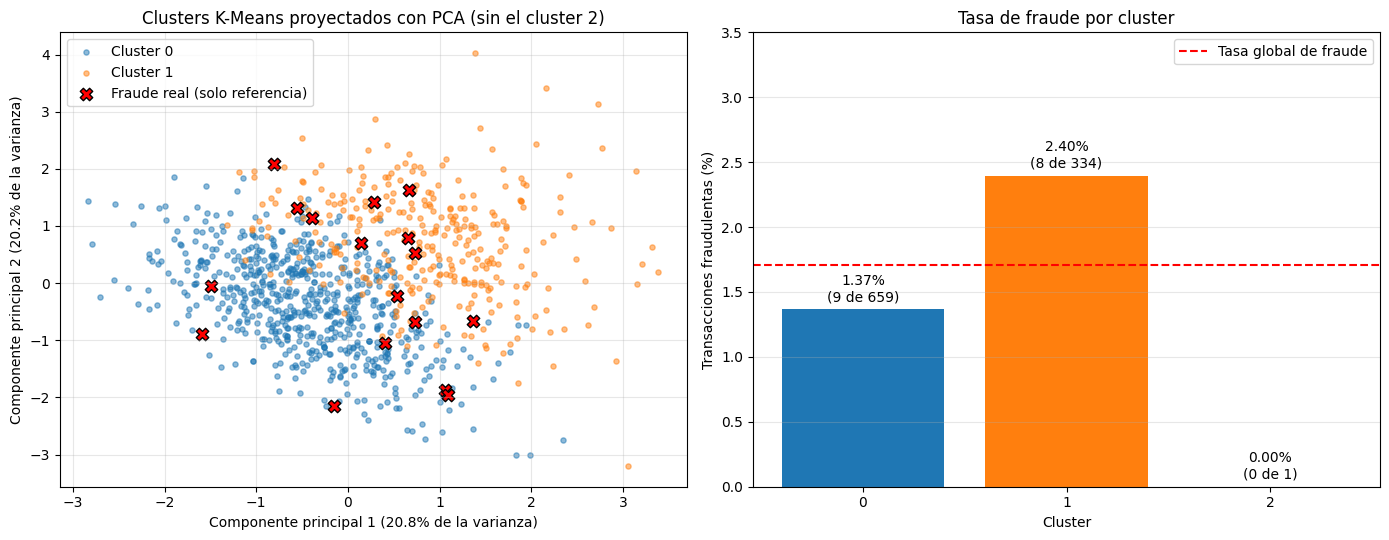

In [151]:
from sklearn.decomposition import PCA

# Visualización de los clusters con PCA (solo para graficar; no se usa para modelar).
# El cluster 2 (1 registro con monto de 95,000 MXN) se excluye del gráfico porque aplastaría al resto de los puntos.
mascara = (df_clusters["cluster"] != 2).values
pca_visual = PCA(n_components=2, random_state=42)
componentes = pca_visual.fit_transform(X_num_escalado[mascara])
grupo = df_clusters.loc[mascara]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel 1: clusters en el plano de las dos primeras componentes principales
for c, color in zip([0, 1], ["tab:blue", "tab:orange"]):
    idx = (grupo["cluster"] == c).values
    ax1.scatter(componentes[idx, 0], componentes[idx, 1], s=14, alpha=0.5, color=color, label=f"Cluster {c}")
idx_fraude = (grupo["fraude"] == 1).values
ax1.scatter(componentes[idx_fraude, 0], componentes[idx_fraude, 1], s=80, marker="X",
            color="red", edgecolor="black", label="Fraude real (solo referencia)")
ax1.set_xlabel(f"Componente principal 1 ({pca_visual.explained_variance_ratio_[0]:.1%} de la varianza)")
ax1.set_ylabel(f"Componente principal 2 ({pca_visual.explained_variance_ratio_[1]:.1%} de la varianza)")
ax1.set_title("Clusters K-Means proyectados con PCA (sin el cluster 2)")
ax1.legend()
ax1.grid(alpha=0.3)

# Panel 2: tasa de fraude por cluster
ax2.bar(perfil_clusters.index.astype(str), perfil_clusters["% fraude"], color=["tab:blue", "tab:orange", "tab:gray"])
ax2.axhline(df_clusters["fraude"].mean() * 100, color="red", linestyle="--", label="Tasa global de fraude")
for i, (tasa, n, f) in enumerate(zip(perfil_clusters["% fraude"], perfil_clusters["Tamaño"], perfil_clusters["Fraudes"])):
    ax2.annotate(f"{tasa:.2f}%\n({f} de {n})", (i, tasa), textcoords="offset points", xytext=(0, 6), ha="center")
ax2.set_xlabel("Cluster")
ax2.set_ylabel("Transacciones fraudulentas (%)")
ax2.set_title("Tasa de fraude por cluster")
ax2.set_ylim(0, 3.5)
ax2.legend()
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretación:** en el panel izquierdo (proyección PCA, que retiene el 41.0% de la varianza con dos componentes) los clusters 0 y 1 aparecen **traslapados**, sin una frontera nítida, lo que es congruente con el coeficiente de silueta bajo de la sección 2.6. Los fraudes reales (X rojas) están dispersos en ambos grupos, sin concentrarse en una zona. En el panel derecho, la tasa de fraude del cluster 1 (2.40%) supera a la del cluster 0 (1.37%) y a la global (1.71%), pero la diferencia es pequeña y se basa en pocos casos.

**Conclusión:** existe un perfil de "IP lejana al envío" con una tasa de fraude algo mayor, pero de forma exploratoria y no significativa. El agrupamiento no revela segmentos de riesgo claramente distintos, por lo que la clasificación supervisada sigue siendo la herramienta principal del proyecto.


### ¿Por qué los clusters no se relacionan con el fraude?

Los grupos de K-Means parecen no guardar relación con el fraude y, entre sí, se traslapan. Para entender por qué, se revisa qué variables definen realmente a cada cluster (sus centroides en unidades estandarizadas, donde 0 es el promedio general) y qué forma tiene la distribución de cada variable numérica.


In [152]:
# ¿Qué variable define a los clusters? Centroides en unidades estandarizadas (0 = promedio general)
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=columnas_numericas,
                          index=[f"Cluster {c}" for c in range(mejor_k)])
print("Centroides de K-Means (variables estandarizadas):")
display(centroides.round(2))

# Forma de la distribución de cada variable numérica (todas las transacciones sin duplicados)
estructura = pd.DataFrame({
    "Asimetría": df_limpio[columnas_numericas].skew(),
    "% de valores iguales a 0": (df_limpio[columnas_numericas] == 0).mean() * 100,
})
corr_num = df_limpio[columnas_numericas].corr().abs().where(~np.eye(len(columnas_numericas), dtype=bool))
print(f"\nMáxima correlación absoluta entre dos variables numéricas distintas: {corr_num.max().max():.2f}")
print("\nForma de la distribución de cada variable:")
estructura.round(2)

Centroides de K-Means (variables estandarizadas):


,monto_mxn,hora,intentos_pago,antiguedad_cuenta_dias,compras_24h,distancia_ip_envio_km
Cluster 0,-0.02,-0.05,0.02,0.08,0.03,-0.60
Cluster 1,-0.02,0.11,-0.04,-0.07,-0.08,1.24
Cluster 2,24.35,0.98,1.51,-0.70,1.49,-0.90



Máxima correlación absoluta entre dos variables numéricas distintas: 0.05

Forma de la distribución de cada variable:


,Asimetría,% de valores iguales a 0
monto_mxn,22.68,0.00
hora,0.01,5.63
intentos_pago,1.09,0.00
antiguedad_cuenta_dias,0.05,0.00
compras_24h,0.36,18.91
distancia_ip_envio_km,1.07,33.00


**Interpretación:** la falta de relación con el fraude es un resultado esperable, por cuatro razones:

1. **Los clusters solo reflejan una variable.** Entre los clusters 0 y 1 la única diferencia importante está en `distancia_ip_envio_km` (centroides de −0.60 y +1.24 desviaciones estándar, una brecha de 1.84); en las demás variables difieren menos de 0.2 desviaciones estándar. El cluster 2 es el de `monto_mxn` (+24.35 desviaciones estándar), es decir, el valor atípico de 95,000 MXN.
2. **K-Means solo puede formar grupos donde hay estructura.** La distancia IP–envío es la única variable con una forma que se presta a separar: el 33% de sus valores son exactamente 0 (compras con IP en el lugar de envío) y el resto tiene una cola larga (asimetría de 1.07). En cambio, `hora` (asimetría 0.01) y `antiguedad_cuenta_dias` (0.05) son distribuciones simétricas sin acumulaciones, y las variables numéricas casi no están correlacionadas entre sí (correlación absoluta máxima de 0.05), por lo que no hay grupos naturales que descubrir. Esto es coherente con el coeficiente de silueta bajo (0.16) y con el traslape que muestra la proyección PCA.
3. **La variable que agrupa no es la que distingue al fraude.** La distancia IP–envío promedia 211 km en los fraudes y 186 km en las transacciones legítimas, prácticamente lo mismo. Las señales que sí distinguen a los fraudes son la hora (promedio de 5.1 frente a 11.3) y que la dirección no coincida (64.7% frente a 21.1%). Sin embargo, la hora no forma grupos, y la coincidencia de dirección es una variable categórica que se excluyó del agrupamiento.
4. **El fraude es una clase muy pequeña y dispersa.** Son 17 transacciones (1.7%) mezcladas dentro de la misma nube que las legítimas, y no una población compacta que K-Means pueda aislar. Lo que caracteriza al fraude es una **combinación de condiciones** (hora temprana, dirección que no coincide, más intentos de pago) y ese tipo de patrón lo encuentran los modelos supervisados, que sí conocen la etiqueta (coeficientes de la regresión logística en 2.13 e importancias del Random Forest en 2.5).

**Conclusión:** que los clusters no se relacionen con el fraude no indica un error en el agrupamiento: es un hallazgo. El aprendizaje no supervisado sobre estas variables describe la estructura de las transacciones (proximidad de la IP al envío), no su riesgo, y por eso la detección de fraude debe apoyarse en los modelos supervisados.


## 2.8 - Construir una Red Neuronal Artificial (MLP)

Se implementa un **Perceptrón Multicapa (MLP)** con `MLPClassifier` de scikit-learn para resolver el mismo problema de clasificación binaria, con el mismo dataset, la misma partición y el mismo preprocesamiento de las secciones 1.12 a 1.14. Se usa scikit-learn (y no Keras/TensorFlow) por consistencia con el resto del proyecto y porque el tamaño del dataset (695 filas de entrenamiento) no requiere una implementación más compleja.

**Arquitectura:** Entradas (21) → 16 neuronas → 8 neuronas → Salida (1 neurona)

Decisiones de diseño:

- **Datos ya escalados:** las redes neuronales son sensibles a la escala de las variables; las numéricas ya están estandarizadas por el pipeline (`StandardScaler`).
- **Desbalance:** `MLPClassifier` no admite `class_weight` (a diferencia de la regresión logística, el árbol, el SVM y el Random Forest de las secciones anteriores) y tampoco se aplica remuestreo (sección 1.13). Por eso el MLP se entrena con la distribución original y se evalúa con el umbral estándar de 0.50; en la sección 2.10 se analiza además qué ocurre con un umbral de 0.20.
- **Sin `early_stopping`:** reservaría el 10% del entrenamiento como validación (unas 70 transacciones), donde quedaría aproximadamente un solo fraude, lo que haría inestable el criterio de parada. En su lugar se fija un máximo de 500 iteraciones.
- `random_state=42` para reproducibilidad.


Iteraciones realizadas: 347 de 500 (el entrenamiento convergió antes del límite)
Pérdida final de entrenamiento (log-loss): 0.0131
ROC-AUC en entrenamiento: 0.9998
ROC-AUC en prueba:        0.8551


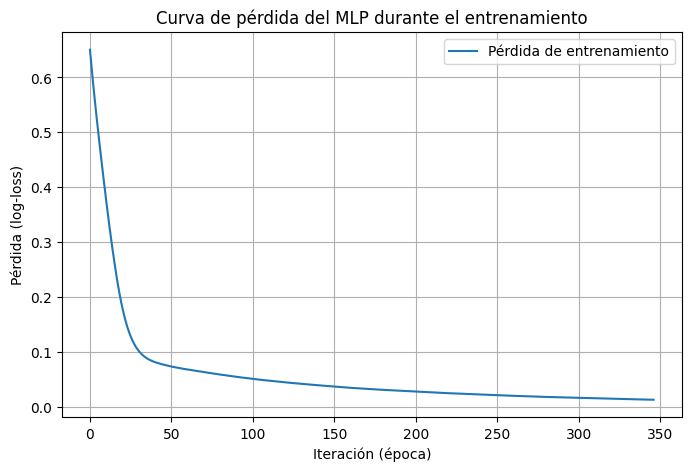

In [153]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score

# Configuración del MLP: entradas (21) -> 16 neuronas -> 8 neuronas -> salida (1 neurona)
mlp = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42,
)

# Entrenamiento (solo con entrenamiento), predicción y probabilidades sobre prueba
mlp.fit(X_train_procesado, y_train)
y_pred_mlp = mlp.predict(X_test_procesado)
y_proba_mlp = mlp.predict_proba(X_test_procesado)[:, 1]

print(f"Iteraciones realizadas: {mlp.n_iter_} de {mlp.max_iter} (el entrenamiento convergió antes del límite)")
print(f"Pérdida final de entrenamiento (log-loss): {mlp.loss_:.4f}")
print(f"ROC-AUC en entrenamiento: {roc_auc_score(y_train, mlp.predict_proba(X_train_procesado)[:, 1]):.4f}")
print(f"ROC-AUC en prueba:        {roc_auc_score(y_test, y_proba_mlp):.4f}")

# Curva de pérdida durante el entrenamiento
plt.figure(figsize=(8, 5))
plt.plot(mlp.loss_curve_, label="Pérdida de entrenamiento")
plt.xlabel("Iteración (época)")
plt.ylabel("Pérdida (log-loss)")
plt.title("Curva de pérdida del MLP durante el entrenamiento")
plt.legend()
plt.grid(True)
plt.show()

**Interpretación:** el entrenamiento convergió antes del límite (347 de las 500 iteraciones permitidas) y la pérdida bajó hasta 0.0131, como muestra la curva. Sin embargo, el ROC-AUC en entrenamiento es prácticamente perfecto (0.9998) frente a 0.8551 en prueba: con 497 parámetros y solo 12 fraudes, la red **memoriza el entrenamiento** (sobreajuste). Esta brecha anticipa que su desempeño con datos nuevos será menos favorable de lo que sugiere el ajuste; se evalúa formalmente en la sección 2.10.


## 2.9 - Documentar la arquitectura del MLP

| Elemento | Configuración |
|---|---|
| Variables de entrada | 21 características (6 numéricas estandarizadas + 15 columnas binarias del One-Hot Encoding) |
| Capa oculta 1 | 16 neuronas, activación ReLU |
| Capa oculta 2 | 8 neuronas, activación ReLU |
| Capa de salida | 1 neurona con activación sigmoide (`logistic`), que produce la probabilidad de fraude |
| Función de pérdida | Log-loss (entropía cruzada binaria) |
| Optimizador | Adam (`solver="adam"`), tasa de aprendizaje de 0.001 (valor por defecto) |
| Regularización | L2 con `alpha=0.0001` (valor por defecto) |
| Iteraciones (épocas) | Máximo de 500; convergió en 347 |
| Parámetros entrenables | 497 (352 + 136 + 9) |
| Random state | 42 |

La siguiente celda obtiene esta información directamente del modelo entrenado, para verificar que coincide con la tabla.


In [154]:
# Arquitectura real del MLP entrenado (obtenida del propio modelo)
tamanos_capas = [mlp.n_features_in_] + list(mlp.hidden_layer_sizes) + [mlp.n_outputs_]
nombres_capas = ["Entrada", "Oculta 1", "Oculta 2", "Salida"]

arquitectura = pd.DataFrame({
    "Capa": nombres_capas,
    "Neuronas": tamanos_capas,
    "Activación": ["-", mlp.activation, mlp.activation, mlp.out_activation_],
    "Parámetros (pesos + sesgos)": [0] + [w.size + b.size for w, b in zip(mlp.coefs_, mlp.intercepts_)],
})
print("Capas totales (entrada + ocultas + salida):", mlp.n_layers_)
print("Parámetros entrenables totales:", arquitectura["Parámetros (pesos + sesgos)"].sum())
print("Solver:", mlp.solver, "| alpha (regularización L2):", mlp.alpha, "| random_state:", mlp.random_state)
arquitectura

Capas totales (entrada + ocultas + salida): 4
Parámetros entrenables totales: 497
Solver: adam | alpha (regularización L2): 0.0001 | random_state: 42


,Capa,Neuronas,Activación,Parámetros (pesos + sesgos)
0,Entrada,21,-,0
1,Oculta 1,16,relu,352
2,Oculta 2,8,relu,136
3,Salida,1,logistic,9


**Interpretación:**

- **¿Qué información recibe la red?** Las 21 características de cada transacción ya preprocesadas: las variables numéricas (monto, hora, intentos de pago, antigüedad de la cuenta, compras en 24 h y distancia IP–envío) estandarizadas, y las variables categóricas (canal, método de pago, dispositivo, país y coincidencia de dirección) convertidas en columnas binarias.
- **¿Cuántas capas ocultas utilizó?** Dos.
- **¿Cuántas neuronas tiene cada capa?** 16 en la primera capa oculta y 8 en la segunda (24 neuronas ocultas en total); la capa de salida tiene 1 neurona.
- **¿Qué función de activación se utilizó?** ReLU en las capas ocultas, que deja pasar los valores positivos y anula los negativos, lo que permite aprender relaciones no lineales; y sigmoide en la neurona de salida, que convierte la señal en una probabilidad entre 0 y 1.
- **¿Cómo genera la clasificación final?** Cada capa calcula combinaciones ponderadas de las salidas de la anterior (21 → 16 → 8 → 1). La neurona de salida entrega la probabilidad estimada de fraude: si es mayor o igual a 0.50 la transacción se clasifica como fraude (1) y en caso contrario como legítima (0). Durante el entrenamiento, el optimizador Adam ajusta los 497 pesos y sesgos para minimizar la log-loss.

Como referencia de complejidad, la regresión logística del modelo preliminar tiene 22 parámetros (21 coeficientes y 1 sesgo), frente a los 497 del MLP.


## 2.10 - Evaluar la red neuronal

Se evalúa el MLP con las mismas métricas que los demás modelos (accuracy, precision, recall, F1-score y ROC-AUC) sobre el mismo conjunto de prueba, y se analizan su matriz de confusión y los conteos de verdaderos negativos (VN), falsos positivos (FP), falsos negativos (FN) y verdaderos positivos (VP). La regresión logística (modelo preliminar) se incluye como referencia directa.


,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,VN,FP,FN,VP
0,Regresión logística,0.8294,0.0577,0.6,0.1053,0.8619,245,49,2,3
1,"MLP (16, 8)",0.9799,0.0000,0.0,0.0000,0.8551,293,1,5,0


MLP -> VN = 293 | FP = 1 | FN = 5 | VP = 0


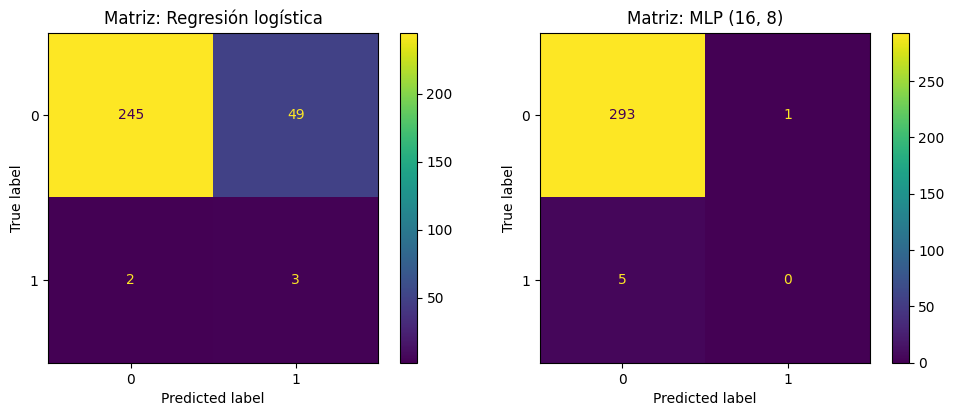

In [155]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Métricas del MLP con las mismas funciones usadas en los demás modelos (umbral 0.50)
predicciones_test["MLP (16, 8)"] = y_pred_mlp
probabilidades_test["MLP (16, 8)"] = y_proba_mlp
resultados_por_modelo["MLP (16, 8)"] = resumen_metricas("MLP (16, 8)", y_test, y_pred_mlp, y_proba_mlp)

tabla_mlp = pd.DataFrame([resultados_por_modelo[n] for n in ["Regresión logística", "MLP (16, 8)"]])
display(tabla_mlp.round(4))

# Conteos de la matriz de confusión del MLP
vn, fp, fn, vp = confusion_matrix(y_test, y_pred_mlp).ravel()
print(f"MLP -> VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}")

# Matrices de confusión: modelo preliminar vs. MLP
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for eje, nombre in zip(axes, ["Regresión logística", "MLP (16, 8)"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predicciones_test[nombre], ax=eje)
    eje.set_title(f"Matriz: {nombre}")
plt.tight_layout()
plt.show()

**Interpretación:** el MLP obtiene un accuracy de 0.9799 y un ROC-AUC de 0.8551, pero su precision, recall y F1-score son 0. Su matriz de confusión es **VN = 293, FP = 1, FN = 5, VP = 0**:

- **VP = 0:** no detecta ninguno de los 5 fraudes.
- **FN = 5:** los 5 fraudes pasan como transacciones legítimas, que es el error más costoso en este contexto (sección 1.18).
- **FP = 1:** solo una transacción supera el umbral de 0.50 y resulta ser legítima.
- **VN = 293:** casi todas las transacciones legítimas se clasifican bien, y ese acierto es lo que infla el accuracy.

La regresión logística, en cambio, detecta 3 de los 5 fraudes (recall = 0.60) con 49 falsos positivos. El MLP casi no genera falsas alarmas porque casi nunca genera alarmas.


In [156]:
# 1. Efecto del umbral de decisión en el MLP (mismos umbrales que en la sección 1.19)
filas_umbral = []
for umbral in [0.50, 0.20]:
    pred_umbral = (y_proba_mlp >= umbral).astype(int)
    vn_u, fp_u, fn_u, vp_u = confusion_matrix(y_test, pred_umbral).ravel()
    filas_umbral.append({
        "Umbral": umbral,
        "Precision": precision_score(y_test, pred_umbral, zero_division=0),
        "Recall": recall_score(y_test, pred_umbral, zero_division=0),
        "F1-score": f1_score(y_test, pred_umbral, zero_division=0),
        "FP": fp_u, "FN": fn_u, "VP": vp_u,
    })
print("MLP - efecto del umbral (conjunto de prueba):")
display(pd.DataFrame(filas_umbral).round(4))

# 2. Estabilidad: la misma arquitectura entrenada con 10 semillas distintas (solo cambia la inicialización)
filas_semillas = []
for semilla in range(10):
    mlp_s = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                          max_iter=500, random_state=semilla).fit(X_train_procesado, y_train)
    pred_s = mlp_s.predict(X_test_procesado)
    proba_s = mlp_s.predict_proba(X_test_procesado)[:, 1]
    filas_semillas.append({"Semilla": semilla, "ROC-AUC": roc_auc_score(y_test, proba_s),
                           "VP": int(((pred_s == 1) & (y_test.values == 1)).sum()),
                           "FP": int(((pred_s == 1) & (y_test.values == 0)).sum())})
tabla_semillas = pd.DataFrame(filas_semillas)
print("\nMLP - variabilidad entre semillas:")
print(f"ROC-AUC: media = {tabla_semillas['ROC-AUC'].mean():.4f} | desv. = {tabla_semillas['ROC-AUC'].std():.4f} "
      f"| mínimo = {tabla_semillas['ROC-AUC'].min():.4f} | máximo = {tabla_semillas['ROC-AUC'].max():.4f}")
print(f"Semillas en las que el MLP detecta al menos 1 fraude con umbral 0.50: {(tabla_semillas['VP'] > 0).sum()} de 10")
tabla_semillas.round(4)

MLP - efecto del umbral (conjunto de prueba):


,Umbral,Precision,Recall,F1-score,FP,FN,VP
0,0.5,0.0,0.0,0.0000,1,5,0
1,0.2,0.1,0.2,0.1333,9,4,1



MLP - variabilidad entre semillas:
ROC-AUC: media = 0.8228 | desv. = 0.0273 | mínimo = 0.7755 | máximo = 0.8823
Semillas en las que el MLP detecta al menos 1 fraude con umbral 0.50: 1 de 10


,Semilla,ROC-AUC,VP,FP
0,0,0.7755,0,4
1,1,0.8333,0,1
2,2,0.8082,0,4
3,3,0.8238,0,2
4,4,0.8048,0,1
5,5,0.8299,0,2
6,6,0.8347,0,4
7,7,0.8823,0,3
8,8,0.8224,1,1
9,9,0.8129,0,4


**Interpretación:**

- **Efecto del umbral:** al bajar el umbral de 0.50 a 0.20, el MLP detecta 1 fraude (recall = 0.20, F1-score = 0.1333), pero genera 9 falsos positivos y sigue muy lejos del recall de la regresión logística.
- **Estabilidad:** al repetir el entrenamiento con 10 semillas distintas, el ROC-AUC en prueba varía entre 0.7755 y 0.8823 (media 0.8228, desviación 0.0273) y, con umbral de 0.50, solo en 1 de las 10 semillas el MLP detecta al menos un fraude. El resultado de la semilla 42 (0.8551) queda por encima del promedio, por lo que la red no es un modelo estable con tan pocos fraudes.

**¿La red neuronal realmente superó a los algoritmos tradicionales? No.**

- En **detección** (precision, recall y F1-score) es igual al baseline (0) y peor que la regresión logística (recall 0.60), el árbol de decisión (0.40) y el RF optimizado (0.20).
- En **ROC-AUC** (0.8551) queda muy cerca de la regresión logística (0.8619), del Random Forest con selección (0.8673) y del SVM (0.8381). Con solo 5 fraudes en prueba esas diferencias no son distinguibles, y en el promedio entre semillas (0.8228) el MLP queda por debajo de la regresión logística.
- Muestra **sobreajuste** (ROC-AUC de 0.9998 en entrenamiento frente a 0.8551 en prueba), requiere 497 parámetros frente a 22 de la regresión logística y es difícil de explicar (caja negra), algo desfavorable en un contexto donde debe justificarse por qué se revisa una transacción.

Un modelo más complejo no es necesariamente un mejor modelo: aquí la red no aporta ventajas y sí costos adicionales de complejidad, inestabilidad y menor interpretabilidad. Con más casos de fraude su desempeño podría cambiar.


## 2.11 - Comparar los modelos

Se consolida el desempeño de todos los modelos desarrollados en el proyecto (baseline, modelos de la primera etapa, modelos adicionales, ensamble, modelo optimizado, modelo con selección de características y red neuronal) sobre el mismo conjunto de prueba (299 transacciones, 5 de ellas fraudulentas). Se reportan las cinco métricas principales y los conteos de falsos positivos (FP) y falsos negativos (FN).

**Cómo leer el resaltado:** en **amarillo** se marca el modelo que se selecciona como final en la sección 2.13 por presentar el mejor desempeño global, aunque no es el mejor en todas las métricas. Las tablas incluyen los falsos positivos (FP) y falsos negativos (FN); el accuracy no se usa para elegir porque en este problema es engañoso (sección 1.11).


In [157]:
# Tabla final con todos los modelos desarrollados en el proyecto (conjunto de prueba)
orden_modelos = ["Baseline (Dummy)", "Regresión logística", "Árbol de decisión", "Random Forest",
                 "Gradient Boosting", "SVM (RBF)", "KNN", "Naive Bayes",
                 "RF optimizado", "RF + selección", "MLP (16, 8)"]
tabla_final = pd.DataFrame([resultados_por_modelo[n] for n in orden_modelos])[
    ["Modelo", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "FP", "FN"]
]

# Resaltado visual: se marca en amarillo el modelo seleccionado como el de mejor desempeño global
# tras el análisis multicriterio de la sección 2.13
MODELO_DESTACADO = "Regresión logística"
def resaltar(tabla):
    estilos = pd.DataFrame("", index=tabla.index, columns=tabla.columns)
    estilos.loc[tabla["Modelo"] == MODELO_DESTACADO, :] = "background-color: #fff2cc; font-weight: bold"
    return estilos

(tabla_final.style
    .apply(resaltar, axis=None)
    .format({"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}",
             "F1-score": "{:.4f}", "ROC-AUC": "{:.4f}"})
    .hide(axis="index"))

Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC,FP,FN
Baseline (Dummy),0.9732,0.0000,0.0000,0.0000,0.4949,3,5
Regresión logística,0.8294,0.0577,0.6000,0.1053,0.8619,49,2
Árbol de decisión,0.8562,0.0476,0.4000,0.0851,0.6350,40,3
Random Forest,0.9833,0.0000,0.0000,0.0000,0.8170,0,5
Gradient Boosting,0.9699,0.0000,0.0000,0.0000,0.8265,4,5
SVM (RBF),0.9431,0.0000,0.0000,0.0000,0.8381,12,5
KNN,0.9833,0.0000,0.0000,0.0000,0.6541,0,5
Naive Bayes,0.1873,0.0163,0.8000,0.0319,0.6316,242,1
RF optimizado,0.9699,0.1667,0.2000,0.1818,0.8048,5,4
RF + selección,0.9666,0.1429,0.2000,0.1667,0.8673,6,4


**Interpretación:** ningún modelo domina en todas las métricas:

- **Mejor precision y F1-score:** RF optimizado (0.1667 y 0.1818), que detecta 1 fraude con solo 5 falsos positivos.
- **Mejor ROC-AUC:** RF + selección (0.8673), seguido de cerca por la regresión logística (0.8619) y el MLP (0.8551).
- **Mayor recall:** Naive Bayes (0.80), pero con 242 falsos positivos, lo que lo hace inviable; entre los modelos aplicables, la regresión logística (0.60).
- **Menor número de FN:** Naive Bayes (1); la regresión logística tiene 2.
- **Menor número de FP entre los que detectan algo:** RF optimizado (5).
- El **accuracy más alto** (0.9833, Random Forest y KNN) corresponde a modelos que no detectan ningún fraude.

De los once modelos, solo cinco detectan al menos un fraude con el umbral de 0.50: la regresión logística (3), el árbol de decisión (2), Naive Bayes (4), RF optimizado (1) y RF + selección (1). Los demás se comportan como el baseline en cuanto a detección. La regresión logística, resaltada en amarillo, es el modelo aplicable con mayor recall (el de Naive Bayes es mayor, pero inviable), con un ROC-AUC entre los tres mejores y un número de falsos positivos manejable; las razones completas se desarrollan en la sección 2.13.


## 2.12 - Visualizar la comparación

Se generan dos gráficas para comparar los modelos: (1) accuracy, precision, recall y F1-score por modelo y (2) ROC-AUC por modelo. Cada gráfica incluye título, etiquetas de ejes, leyenda y una breve interpretación. El modelo resaltado en la sección 2.11 se muestra en naranja.


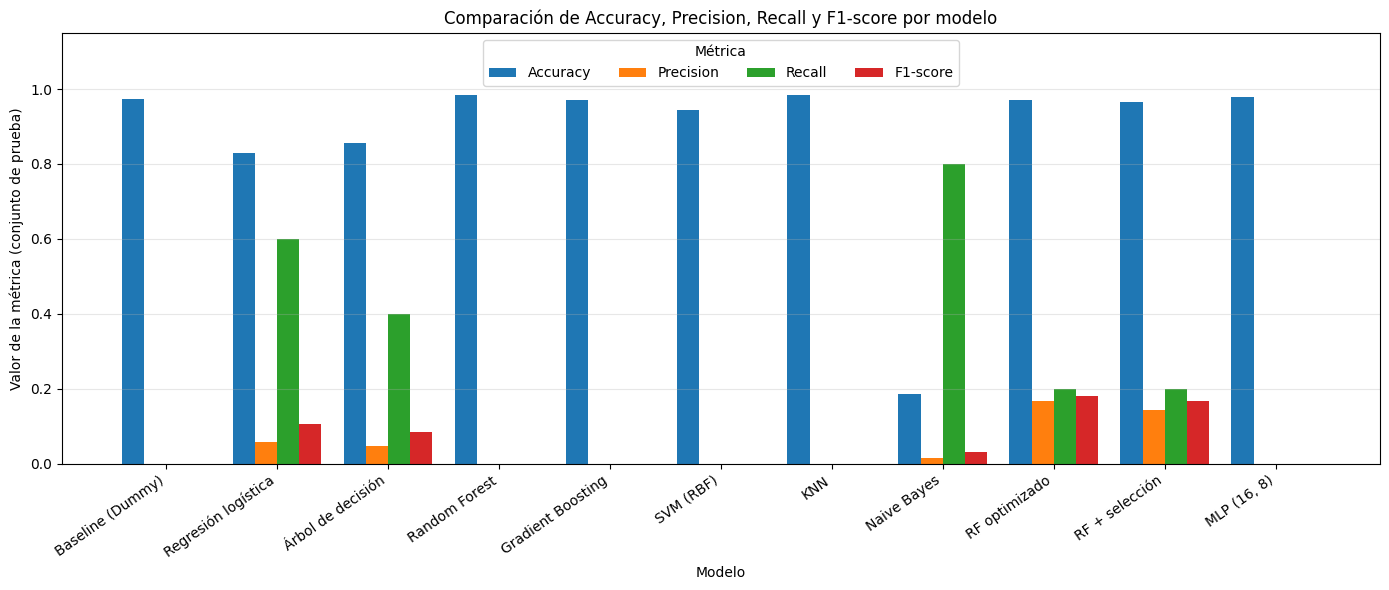

In [158]:
import matplotlib.pyplot as plt

# Gráfica 1: Accuracy, Precision, Recall y F1-score por modelo
metricas_barras = ["Accuracy", "Precision", "Recall", "F1-score"]
posiciones = np.arange(len(tabla_final))
ancho = 0.2

plt.figure(figsize=(14, 6))
for i, metrica in enumerate(metricas_barras):
    plt.bar(posiciones + (i - 1.5) * ancho, tabla_final[metrica], width=ancho, label=metrica)
plt.xticks(posiciones, tabla_final["Modelo"], rotation=35, ha="right")
plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica (conjunto de prueba)")
plt.title("Comparación de Accuracy, Precision, Recall y F1-score por modelo")
plt.ylim(0, 1.15)
plt.legend(title="Métrica", loc="upper center", ncol=4)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación (Gráfica 1):** las barras de accuracy son muy altas (0.94 o más) en la mayoría de los modelos y solo bajan en los que más alertas emiten: regresión logística (0.83), árbol de decisión (0.86) y Naive Bayes (0.19). Esto confirma que el accuracy premia a los modelos que no detectan fraude. Las demás métricas muestran otra realidad: solo cinco modelos tienen barras visibles de precision, recall y F1-score. Naive Bayes tiene el mayor recall (0.80) con precision casi nula; la regresión logística combina el segundo mayor recall (0.60) con una precision baja (0.058); y RF optimizado y RF + selección tienen la mayor precision y F1-score (entre 0.14 y 0.18), pero con un recall de solo 0.20.


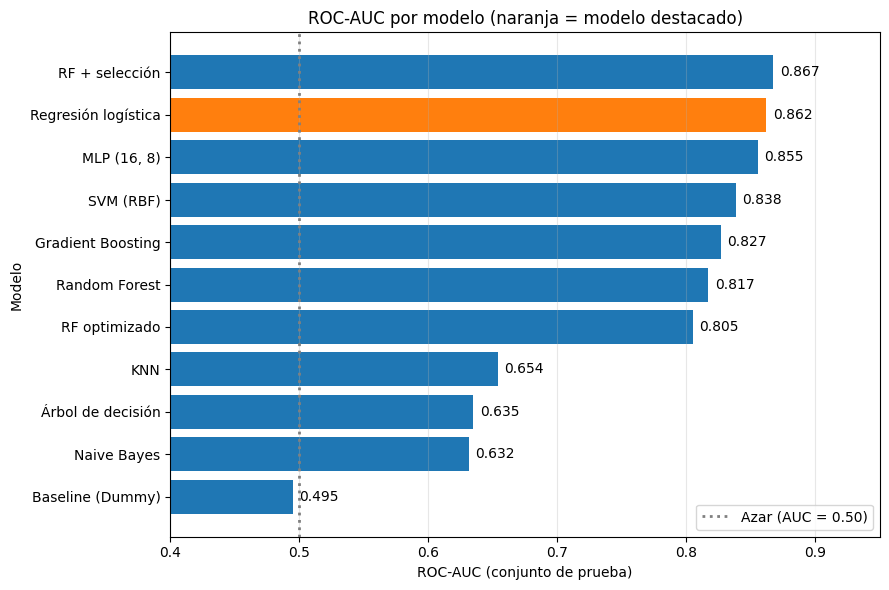

In [159]:
# Gráfica 2: ROC-AUC por modelo
orden_auc = tabla_final.sort_values("ROC-AUC")
colores_auc = ["tab:orange" if m == MODELO_DESTACADO else "tab:blue" for m in orden_auc["Modelo"]]

plt.figure(figsize=(9, 6))
plt.barh(orden_auc["Modelo"], orden_auc["ROC-AUC"], color=colores_auc)
plt.axvline(0.5, color="gray", linestyle=":", linewidth=2, zorder=3, label="Azar (AUC = 0.50)")
for i, valor in enumerate(orden_auc["ROC-AUC"]):
    plt.text(valor + 0.005, i, f"{valor:.3f}", va="center")
plt.xlabel("ROC-AUC (conjunto de prueba)")
plt.ylabel("Modelo")
plt.title("ROC-AUC por modelo (naranja = modelo destacado)")
plt.xlim(0.4, 0.95)
plt.legend(loc="lower right")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretación (Gráfica 2):** todos los modelos superan el azar (AUC = 0.50), salvo el baseline (0.495). Se distinguen dos grupos: siete modelos con ROC-AUC entre 0.805 y 0.867 (RF + selección, regresión logística, MLP, SVM, Gradient Boosting, Random Forest y RF optimizado) y cuatro por debajo de 0.66 (KNN, árbol de decisión, Naive Bayes y baseline). Dentro del primer grupo las diferencias son de unas pocas centésimas y, con 5 fraudes en prueba, no son estadísticamente distinguibles. Por eso el ROC-AUC por sí solo no basta para elegir el modelo: SVM, Gradient Boosting, Random Forest y MLP tienen un AUC alto y aun así detectan 0 fraudes con el umbral de 0.50.


## 2.13 - Seleccionar el modelo final

La elección del modelo final **no puede basarse solo en el accuracy** ni en una única métrica: en este problema el accuracy más alto pertenece a modelos que no detectan ningún fraude (sección 2.11). Se consideran de forma conjunta la precision, el recall, el F1-score, el ROC-AUC, los falsos positivos y falsos negativos, el desbalance de clases, la interpretabilidad, la complejidad, el contexto del problema (sección 1.2) y el riesgo de una predicción incorrecta (sección 1.18).

Como en la sección 1.20, la decisión no debe depender únicamente del conjunto de prueba, que contiene apenas 5 fraudes. Por eso se agrega evidencia de **validación cruzada repetida (5 folds × 5 repeticiones) sobre el conjunto de entrenamiento**, con predicciones *out-of-fold* y con el preprocesamiento reajustado dentro de cada fold. El conjunto de prueba se usa como confirmación y no como único criterio.


In [160]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score

# Función auxiliar: validación cruzada repetida (5 folds x 5 repeticiones) con predicciones "out-of-fold".
# El preprocesamiento (y la selección de características) se reajustan dentro de cada fold; X_test no participa.
def validacion_cruzada_oof(pipeline, repeticiones=5):
    filas = []
    for r in range(repeticiones):
        cv_r = StratifiedKFold(n_splits=5, shuffle=True, random_state=r)
        proba = cross_val_predict(pipeline, X_train, y_train, cv=cv_r, method="predict_proba")[:, 1]
        pred = (proba >= 0.50).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_train, pred).ravel()
        filas.append([roc_auc_score(y_train, proba), average_precision_score(y_train, proba), vp, fp, fn])
    filas = np.array(filas)
    return {
        "ROC-AUC (media)": filas[:, 0].mean(),
        "ROC-AUC (desv.)": filas[:, 0].std(),
        "Average Precision": filas[:, 1].mean(),
        "VP (de 12)": filas[:, 2].mean(),
        "FP (de 683)": filas[:, 3].mean(),
        "FN (de 12)": filas[:, 4].mean(),
    }

# Pipeline del modelo con selección de características (el selector se ajusta dentro de cada fold)
pipeline_rf_seleccion = Pipeline([
    ("preprocesamiento", preprocesador),
    ("seleccion", SelectFromModel(RandomForestClassifier(**busqueda.best_params_, random_state=42, n_jobs=-1),
                                  threshold="median")),
    ("modelo", RandomForestClassifier(**busqueda.best_params_, random_state=42, n_jobs=-1)),
])

# Evidencia adicional para elegir sin apoyarse solo en 5 fraudes de prueba:
# validación cruzada repetida (5x5) sobre el ENTRENAMIENTO, con el preprocesamiento reajustado en cada fold
modelos_para_cv = {
    "Regresión logística": clone(modelo_lr),
    "Árbol de decisión": clone(modelo_dt),
    "Random Forest": clone(modelos_entrenados["Random Forest"]),
    "Gradient Boosting": clone(modelos_entrenados["Gradient Boosting"]),
    "SVM (RBF)": clone(modelos_entrenados["SVM (RBF)"]),
    "KNN": clone(modelos_entrenados["KNN"]),
    "Naive Bayes": clone(modelos_entrenados["Naive Bayes"]),
    "RF optimizado": clone(rf_optimizado),
    "MLP (16, 8)": clone(mlp),
}
resultados_cv_finales = {}
for nombre, modelo in modelos_para_cv.items():
    pipeline_cv = Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])
    resultados_cv_finales[nombre] = validacion_cruzada_oof(pipeline_cv)
resultados_cv_finales["RF + selección"] = validacion_cruzada_oof(pipeline_rf_seleccion)

tabla_cv_finales = pd.DataFrame(resultados_cv_finales).T.sort_values("ROC-AUC (media)", ascending=False)
print("Validación cruzada repetida (5 folds x 5 repeticiones) sobre entrenamiento, umbral 0.50:")
tabla_cv_finales.round(3)

Validación cruzada repetida (5 folds x 5 repeticiones) sobre entrenamiento, umbral 0.50:


,ROC-AUC (media),ROC-AUC (desv.),Average Precision,VP (de 12),FP (de 683),FN (de 12)
"MLP (16, 8)",0.835,0.042,0.127,0.2,1.8,11.8
Regresión logística,0.809,0.034,0.125,5.0,77.6,7.0
RF + selección,0.745,0.037,0.067,0.6,9.0,11.4
RF optimizado,0.734,0.067,0.056,0.6,5.4,11.4
Gradient Boosting,0.728,0.020,0.056,0.0,2.4,12.0
SVM (RBF),0.704,0.053,0.048,0.0,0.2,12.0
Random Forest,0.661,0.083,0.036,0.0,0.8,12.0
Naive Bayes,0.636,0.036,0.045,10.8,528.2,1.2
KNN,0.620,0.019,0.051,0.0,0.8,12.0
Árbol de decisión,0.534,0.042,0.022,1.8,54.4,10.2


**Interpretación (validación cruzada repetida):**

- **Ordenamiento (ROC-AUC y Average Precision):** el MLP (0.835) y la regresión logística (0.809) son los mejores y están empatados dentro de una desviación estándar (0.042 y 0.034; Average Precision de 0.127 y 0.125). Los modelos basados en árboles y el SVM quedan claramente por debajo (entre 0.53 y 0.75), incluidos RF optimizado (0.734) y RF + selección (0.745): la ventaja de RF + selección en el conjunto de prueba (0.8673) **no se confirma** en validación cruzada.
- **Detección con umbral de 0.50:** la regresión logística detecta en promedio 5.0 de los 12 fraudes de entrenamiento (recall cercano a 0.42), mientras que RF + selección y RF optimizado detectan 0.6, el MLP 0.2, y Random Forest, Gradient Boosting, SVM y KNN prácticamente ninguno. Naive Bayes detecta 10.8, pero con cerca de 528 falsos positivos.
- **Costo de detectar:** la regresión logística genera en promedio 77.6 falsos positivos sobre 683 transacciones legítimas (cerca del 11%).


In [161]:
# Costo de equilibrio: ¿cuántas veces debe costar un fraude no detectado (FN) más que una revisión
# innecesaria (FP) para que la regresión logística sea preferible a cada alternativa? (conjunto de prueba)
lr_res = resultados_por_modelo["Regresión logística"]
perdida_media_fraude = df_limpio.loc[df_limpio["fraude"] == 1, "monto_mxn"].mean()

filas_costo = []
for nombre in ["Árbol de decisión", "Random Forest", "Gradient Boosting", "SVM (RBF)", "KNN",
               "RF optimizado", "RF + selección", "MLP (16, 8)"]:
    alt = resultados_por_modelo[nombre]
    fp_extra = lr_res["FP"] - alt["FP"]      # revisiones adicionales que genera la regresión logística
    fn_evitados = alt["FN"] - lr_res["FN"]   # fraudes adicionales que detecta la regresión logística
    razon = fp_extra / fn_evitados
    filas_costo.append({
        "Alternativa": nombre,
        "FP extra de la LR": fp_extra,
        "FN evitados por la LR": fn_evitados,
        "Razón costo FN / costo FP de equilibrio": razon,
        "Costo máx. por revisión (MXN)": perdida_media_fraude / razon,
    })
print(f"Pérdida media por fraude (monto promedio de las 17 transacciones fraudulentas): {perdida_media_fraude:,.0f} MXN")
print("La regresión logística es preferible si un fraude no detectado cuesta más de la razón indicada")
print("veces una revisión manual innecesaria (o, equivalentemente, si la revisión cuesta menos que el último valor).\n")
pd.DataFrame(filas_costo).round(2)

Pérdida media por fraude (monto promedio de las 17 transacciones fraudulentas): 1,741 MXN
La regresión logística es preferible si un fraude no detectado cuesta más de la razón indicada
veces una revisión manual innecesaria (o, equivalentemente, si la revisión cuesta menos que el último valor).



,Alternativa,FP extra de la LR,FN evitados por la LR,Razón costo FN / costo FP de equilibrio,Costo máx. por revisión (MXN)
0,Árbol de decisión,9,1,9.00,193.40
1,Random Forest,49,3,16.33,106.57
2,Gradient Boosting,45,3,15.00,116.04
3,SVM (RBF),37,3,12.33,141.13
4,KNN,49,3,16.33,106.57
5,RF optimizado,44,2,22.00,79.12
6,RF + selección,43,2,21.50,80.96
7,"MLP (16, 8)",48,3,16.00,108.79


**Interpretación (costo de equilibrio):** la regresión logística genera más falsas alarmas que las alternativas, pero también detecta más fraudes. La tabla indica cuántas veces más costoso debe ser un fraude no detectado que una revisión innecesaria para que la regresión logística sea preferible. Frente a RF + selección, por ejemplo, lo es si un fraude no detectado cuesta más de 21.5 veces una revisión; con la pérdida media observada por fraude (1,741 MXN) eso equivale a que cada revisión cueste menos de 81 MXN. Frente al resto de las alternativas el umbral es todavía menor (entre 9 y 22 veces), de modo que **si una revisión manual cuesta menos de unos 79 MXN, la regresión logística es preferible a todas las alternativas evaluadas**. El costo real de revisión debe confirmarlo la organización; el cálculo es ilustrativo, supone que la pérdida por fraude equivale al monto de la transacción y se basa en solo 5 fraudes de prueba.


In [162]:
# Interpretabilidad de la regresión logística: coeficientes (variables ya estandarizadas)
coeficientes = pd.DataFrame({
    "Característica": nombres_finales,
    "Coeficiente": modelo_lr.coef_[0],
}).sort_values("Coeficiente", key=abs, ascending=False).reset_index(drop=True)
coeficientes["Efecto sobre el riesgo de fraude"] = np.where(coeficientes["Coeficiente"] > 0, "aumenta", "disminuye")
coeficientes.head(8).round(3)

,Característica,Coeficiente,Efecto sobre el riesgo de fraude
0,hora,-2.471,disminuye
1,pais_MÉXICO,2.450,aumenta
2,direccion_coincide_SÍ,-1.736,disminuye
3,direccion_coincide_NO,1.734,aumenta
4,intentos_pago,1.700,aumenta
5,pais_COLOMBIA,-1.666,disminuye
6,dispositivo_MÓVIL,0.965,aumenta
7,compras_24h,0.933,aumenta


**Interpretación (interpretabilidad de la regresión logística):** los coeficientes están expresados sobre variables estandarizadas, por lo que su magnitud es comparable. Los de mayor peso son `hora` (−2.47: a horas más tempranas, mayor riesgo), `intentos_pago` (+1.70: más intentos de pago, mayor riesgo), `direccion_coincide_NO` (+1.73: la dirección de envío no coincide con la de facturación, mayor riesgo) y `compras_24h` (+0.93). Son señales coherentes con el contexto del negocio y con las variables que el Random Forest identificó como importantes en la sección 2.5. Los coeficientes de país (`pais_MÉXICO` +2.45, `pais_COLOMBIA` −1.67) deben leerse con cautela: son relativos a las demás categorías, dependen de muy pocos fraudes por país y `pais_MEXICO` y `pais_MÉXICO` quedaron como categorías separadas en el preprocesamiento.


### Modelo final seleccionado: regresión logística

**Decisión:** se selecciona la **regresión logística** (`class_weight="balanced"`) como modelo final para apoyar la priorización de transacciones que deben revisarse manualmente.

**Comparación de criterios entre los modelos finalistas:**

| Criterio | Regresión logística | RF + selección | RF optimizado | MLP (16, 8) |
|---|---|---|---|---|
| Recall (prueba) | 0.60 (3 de 5) | 0.20 (1 de 5) | 0.20 (1 de 5) | 0.00 (0 de 5) |
| Precision (prueba) | 0.0577 | 0.1429 | 0.1667 | 0.0000 |
| F1-score (prueba) | 0.1053 | 0.1667 | 0.1818 | 0.0000 |
| ROC-AUC (prueba) | 0.8619 | 0.8673 | 0.8048 | 0.8551 |
| ROC-AUC (validación cruzada 5×5) | 0.809 | 0.745 | 0.734 | 0.835 |
| FP / FN (prueba) | 49 / 2 | 6 / 4 | 5 / 4 | 1 / 5 |
| Interpretabilidad | Alta: los coeficientes explican cada predicción | Media: importancias globales, sin explicación por caso | Media: igual que RF + selección | Baja: caja negra |
| Complejidad | Baja (22 parámetros) | Media (50 árboles, 11 variables) | Media (50 árboles, 21 variables) | Alta (497 parámetros) |
| Estabilidad | Determinista; ROC-AUC similar en validación y prueba | Su ventaja en prueba no se confirma en validación | Su mejora depende de un solo fraude | ROC-AUC entre 0.78 y 0.88 según la semilla |

**¿Por qué este modelo es más apropiado?**

1. **Riesgo y costo del error:** el error más costoso es no detectar un fraude (FN). La regresión logística es el único modelo que combina una detección útil (recall de 0.60 en prueba y cercano a 0.42 en validación cruzada) con falsas alarmas manejables. Los modelos con menos falsos positivos (RF optimizado, RF + selección, Gradient Boosting, SVM y MLP) detectan entre 0 y 1 de los 5 fraudes, es decir, dejan el fraude prácticamente sin detectar. El análisis de costo de equilibrio muestra que la regresión logística es preferible mientras una revisión manual cueste menos de unos 79 MXN, frente a una pérdida media de 1,741 MXN por fraude.
2. **Capacidad de ordenar por riesgo:** su ROC-AUC es consistente en ambas evaluaciones (0.809 en validación cruzada y 0.862 en prueba) y figura entre los mejores en las dos. En cambio, la ventaja de RF + selección en prueba no se confirma en validación cruzada, y el MLP, aunque empata en ordenamiento, no traduce ese ordenamiento en detecciones con el umbral de 0.50.
3. **Desbalance de clases:** `class_weight="balanced"` le permite prestar atención a la clase minoritaria sin recurrir a remuestreo (sección 1.13).
4. **Interpretabilidad y complejidad:** con 22 parámetros y coeficientes que indican cómo cada variable aumenta o disminuye el riesgo, permite justificar ante el equipo de fraude por qué una transacción se envía a revisión. Es determinista y no depende de una semilla, a diferencia del MLP.

**¿Por qué no los demás?** Naive Bayes marca más del 80% de las transacciones legítimas como fraude. El árbol de decisión detecta menos fraudes con menor ROC-AUC (0.6350). Random Forest, Gradient Boosting, SVM y KNN no detectan ningún fraude con el umbral de 0.50. RF optimizado y RF + selección reducen las falsas alarmas, pero detectan solo 1 de 5 fraudes, con una ganancia que depende de un único caso. El MLP no supera a la regresión logística y es más complejo, menos estable y menos interpretable (sección 2.10).

**Limitaciones y uso recomendado:**

- Con el umbral de 0.50 la regresión logística envía a revisión 52 de 299 transacciones (17.4%) y captura 3 de los 5 fraudes; su precision es de 5.8%, unas 3.5 veces la tasa base de fraude (1.7%), por lo que **debe usarse como una herramienta de priorización y no como una decisión automática de bloqueo** (sección 1.2). Con un umbral de 0.20 (sección 1.19) el recall sube a 0.80 a costa de 65 falsos positivos.
- **Salvedades de la comparación:** todos los modelos se compararon con el umbral estándar de 0.50 y la regresión logística no fue optimizada en esta etapa (sí lo fue el Random Forest). Parte de su ventaja en detección se debe a que `class_weight="balanced"` desplaza sus probabilidades hacia arriba; modelos con un ROC-AUC similar (MLP, SVM, Gradient Boosting) podrían acercarse con un umbral ajustado. Además, el análisis de costo de equilibrio usa los conteos del conjunto de prueba, por lo que la decisión no es totalmente independiente de él, aunque la validación cruzada la respalda.
- El umbral de operación debe definirse con los costos reales de una revisión y de un fraude no detectado.
- El dataset contiene solo 17 fraudes, por lo que la selección es **provisional**: conviene reevaluarla con más datos y monitorear el modelo una vez en operación.


In [163]:
# Modelo final seleccionado
modelo_final = "Regresión logística"
metricas_finales = resultados_por_modelo[modelo_final]

print(f"Modelo final seleccionado: {modelo_final} (class_weight='balanced', umbral inicial 0.50)")
print(f"Desempeño en prueba -> Recall: {metricas_finales['Recall']:.2f} | Precision: {metricas_finales['Precision']:.4f} "
      f"| ROC-AUC: {metricas_finales['ROC-AUC']:.4f} | FP: {metricas_finales['FP']} | FN: {metricas_finales['FN']}")
print(f"Transacciones enviadas a revisión: {metricas_finales['FP'] + metricas_finales['VP']} de {len(y_test)} "
      f"({(metricas_finales['FP'] + metricas_finales['VP']) / len(y_test):.1%})")

Modelo final seleccionado: Regresión logística (class_weight='balanced', umbral inicial 0.50)
Desempeño en prueba -> Recall: 0.60 | Precision: 0.0577 | ROC-AUC: 0.8619 | FP: 49 | FN: 2
Transacciones enviadas a revisión: 52 de 299 (17.4%)


In [164]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np

# 1. Definir las listas de variables numéricas y categóricas
variables_numericas = [
    'monto_mxn',
    'hora',
    'intentos_pago',
    'antiguedad_cuenta_dias',
    'compras_24h',
    'distancia_ip_envio_km'
]

variables_categoricas = [
    'canal',
    'metodo_pago',
    'dispositivo',
    'pais',
    'direccion_coincide'
]

# 2. Transformador personalizado para limpiar texto en variables categóricas
# (corrige espacios y mayúsculas/minúsculas detectadas en la exploración)
class TextNormalizer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Convertir a DataFrame si es un array numpy y aplicar limpieza de texto
        X_copy = pd.DataFrame(X).copy()
        for col in X_copy.columns:
            X_copy[col] = X_copy[col].astype(str).str.strip().str.title()
            # Manejar strings de valores nulos si quedaron como texto 'Nan' o 'None'
            X_copy[col] = X_copy[col].replace(['Nan', 'None', 'Na'], np.nan)
        return X_copy

# 3. Sub-pipeline para variables numéricas (Sección 14.1)
# - Imputación con la mediana (robusta a valores atípicos en monto_mxn)
# - Escalado estándar
pipeline_numerico = Pipeline(steps=[
    ('imputador_mediana', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler())
])

# 4. Sub-pipeline para variables categóricas (Sección 14.2)
# - Normalización de texto
# - Imputación con la moda (valor más frecuente)
# - One-Hot Encoding ignorando categorías desconocidas en prueba
pipeline_categorico = Pipeline(steps=[
    ('normalizador', TextNormalizer()),
    ('imputador_moda', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 5. ColumnTransformer principal nombrado como 'pipeline'
pipeline = ColumnTransformer(
    transformers=[
        ('num', pipeline_numerico, variables_numericas),
        ('cat', pipeline_categorico, variables_categoricas)
    ]
)

# 6. Ajustar y verificar dimensiones
X_train_procesado = pipeline.fit_transform(X_train)
X_test_procesado = pipeline.transform(X_test)

print("Dimensiones de X_train procesado:", X_train_procesado.shape)
print("Dimensiones de X_test procesado:", X_test_procesado.shape)

Dimensiones de X_train procesado: (695, 21)
Dimensiones de X_test procesado: (299, 21)


In [227]:
import pandas as pd

# 1. Definir un nuevo caso de transacción sospechosa
nuevo_caso = pd.DataFrame({
    'monto_mxn': [45000.00],
    'hora': [3],
    'canal': ['Web'],
    'metodo_pago': ['Tarjeta'],
    'dispositivo': ['Móvil'],
    'pais': ['México'],
    'intentos_pago': [4],
    'antiguedad_cuenta_dias': [2],
    'direccion_coincide': ['No'],
    'compras_24h': [5],
    'distancia_ip_envio_km': [850.0]
})

# 2. Transformar el caso con el pipeline ya existente
caso_procesado = pipeline.transform(nuevo_caso)

# 3. Predecir usando tu modelo de Regresión Logística (reemplaza 'modelo_regresion_logistica'
# por el nombre exacto de la variable de tu modelo entrenado, o usa el tuyo)
probabilidad_fraude = modelo_regresion_logistica.predict_proba(caso_procesado)[0][1]

print(f"Probabilidad estimada de fraude: {probabilidad_fraude:.2f}")
print(f"Predicción con umbral 0.50: {'Clase 1 (Fraude)' if probabilidad_fraude >= 0.50 else 'Clase 0 (Legítima)'}")

NameError: name 'modelo_regresion_logistica' is not defined